# Imports

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import glob
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plt.rcParams['figure.figsize'] = [15, 8]

# Load data

In [2]:
DATA_DIR = '../../data/second_batch(EDA)/'
CATEGORY = "industrial"

In [3]:
all_files = glob.glob(DATA_DIR + CATEGORY + "/*.csv")


df_list = []

for id, filename in enumerate(all_files):
    df = pd.read_csv(filename, index_col=0, header=0)
    if CATEGORY == "industrial":
        if id in [0, 2]:
            df.index = pd.to_datetime(df.index, format='%Y-%m-%d %H:%M:%S')
        else:
            df.index = pd.to_datetime(df.index, format='%Y/%m/%d, %H:%M')#"mixed") # 
        df['site_id'] = id+1
        df_list.append(df)

        
    
    

df = pd.concat(df_list, axis=0, ignore_index=False)
df = df.reset_index(names='timestamp')
del df_list
df

,timestamp,[ kWh ],site_id,avg_power,min,max,P+ total,Q+ total
0,2023-02-26 01:30:00,0.552500,1,NaN,NaN,NaN,NaN,NaN
1,2023-02-26 01:45:00,0.552500,1,NaN,NaN,NaN,NaN,NaN
2,2023-02-26 02:00:00,0.544000,1,NaN,NaN,NaN,NaN,NaN
3,2023-02-26 02:15:00,0.544000,1,NaN,NaN,NaN,NaN,NaN
4,2023-02-26 02:30:00,0.544000,1,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
361161,2025-04-24 19:00:00,0.288000,9,NaN,NaN,NaN,NaN,NaN
361162,2025-04-24 19:15:00,0.246514,9,NaN,NaN,NaN,NaN,NaN
361163,2025-04-24 19:30:00,0.647886,9,NaN,NaN,NaN,NaN,NaN
361164,2025-04-24 19:45:00,0.357829,9,NaN,NaN,NaN,NaN,NaN


In [4]:
df.describe()

,timestamp,[ kWh ],site_id,avg_power,min,max,P+ total,Q+ total
count,361166,197797.000000,361166.000000,57603.000000,57603.000000,57603.000000,105766.000000,70510.000000
mean,2024-08-01 14:45:14.667493888,6.331913,4.368421,8.026648,6.894049,9.101487,11.491650,0.000270
min,2023-02-26 01:30:00,0.000000,1.000000,0.000000,0.000000,0.000000,0.031771,0.000000
25%,2024-05-12 02:18:45,0.287842,2.000000,3.500576,1.875000,4.725000,9.296680,0.000000
50%,2024-09-14 14:45:00,0.631000,4.000000,4.624180,4.500000,4.881356,10.312500,0.000000
75%,2024-12-28 02:00:00,6.880000,7.000000,5.000000,4.862903,5.175000,13.669982,0.000000
max,2025-04-24 20:30:00,80.372093,9.000000,74.754098,72.000000,82.983051,41.160156,0.220000
std,NaN,11.338614,2.600526,10.702278,10.255015,11.374492,3.923975,0.004141


# Data preprocessing

## Missing values (without filled minutes)

In [5]:
pd.concat(
    [df.count(), df.isna().sum(), (df.isna().sum()/df.shape[0])*100],
    axis=1).rename(columns={0:'total', 1:'missing', 2:'missing_perc'})

,total,missing,missing_perc
timestamp,361166,0,0.000000
[ kWh ],197797,163369,45.233771
site_id,361166,0,0.000000
avg_power,57603,303563,84.050824
min,57603,303563,84.050824
max,57603,303563,84.050824
P+ total,105766,255400,70.715405
Q+ total,70510,290656,80.477121


## Amount of industrial sites and their available data

In [6]:
df['site_id'].value_counts().sort_index()

site_id
1    70073
2    28806
3    70073
4    28801
5    35255
6    35256
7    35255
8    28802
9    28845
Name: count, dtype: int64

## Time range

In [7]:
print('We have data from:', df['timestamp'].min(),
      '\nuntil:', df['timestamp'].max())


We have data from: 2023-02-26 01:30:00 
until: 2025-04-24 20:30:00


In [8]:
df.groupby('site_id')['timestamp'].agg(['min', 'max'])

,min,max
site_id,,
1,2023-02-26 01:30:00,2025-02-24 23:30:00
2,2024-06-28 09:00:00,2025-04-24 10:15:00
3,2023-02-26 01:30:00,2025-02-24 23:30:00
4,2024-06-28 09:00:00,2025-04-24 20:00:00
5,2024-04-22 14:45:00,2025-04-24 20:15:00
6,2024-04-22 14:45:00,2025-04-24 20:30:00
7,2024-04-22 15:00:00,2025-04-24 20:30:00
8,2024-06-28 09:00:00,2025-04-24 20:00:00
9,2024-06-28 09:00:00,2025-04-24 20:00:00


## Time frequency
15 minutes between rows

In [9]:
for site_id, group in df.groupby('site_id'):
    print(f"\nSite {site_id} has time difference statistics:")
    print(group['timestamp'].diff().describe())


Site 1 has time difference statistics:
count              70072
mean     0 days 00:15:00
std      0 days 00:00:00
min      0 days 00:15:00
25%      0 days 00:15:00
50%      0 days 00:15:00
75%      0 days 00:15:00
max      0 days 00:15:00
Name: timestamp, dtype: object

Site 2 has time difference statistics:
count                        28805
mean               0 days 00:15:00
std      0 days 00:00:29.997916883
min              -1 days +23:15:00
25%                0 days 00:15:00
50%                0 days 00:15:00
75%                0 days 00:15:00
max                0 days 01:15:00
Name: timestamp, dtype: object

Site 3 has time difference statistics:
count              70072
mean     0 days 00:15:00
std      0 days 00:00:00
min      0 days 00:15:00
25%      0 days 00:15:00
50%      0 days 00:15:00
75%      0 days 00:15:00
max      0 days 00:15:00
Name: timestamp, dtype: object

Site 4 has time difference statistics:
count                        28800
mean        0 days 00:15:01.3750

In [10]:
for site_id, group in df.groupby('site_id'):
    print(f"\nSite {site_id} weird rows:")
    diff_data = group['timestamp'].diff().fillna(pd.Timedelta(minutes=15))
    weird_index = group.loc[diff_data != pd.Timedelta(minutes=15)].index
    # combine weird index with the weird index - 1 data
    weird_index_minus_one = weird_index.union(weird_index - 1)
    # get rid of -1 index
    weird_index_minus_one = weird_index_minus_one[weird_index_minus_one >= 0]
    display(
        group.loc[weird_index_minus_one]
        )


Site 1 weird rows:


,timestamp,[ kWh ],site_id,avg_power,min,max,P+ total,Q+ total



Site 2 weird rows:


,timestamp,[ kWh ],site_id,avg_power,min,max,P+ total,Q+ total
81664,2024-10-27 02:45:00,0.560000,2,NaN,NaN,NaN,NaN,NaN
81665,2024-10-27 02:00:00,0.287785,2,NaN,NaN,NaN,NaN,NaN
96448,2025-03-30 01:45:00,0.264046,2,NaN,NaN,NaN,NaN,NaN
96449,2025-03-30 03:00:00,0.278996,2,NaN,NaN,NaN,NaN,NaN



Site 3 weird rows:


,timestamp,[ kWh ],site_id,avg_power,min,max,P+ total,Q+ total


... (8 outputs left out)


Site 8 weird rows:


,timestamp,[ kWh ],site_id,avg_power,min,max,P+ total,Q+ total
315110,2024-10-27 02:45:00,NaN,8,1.600000,0.000000,4.800000,NaN,NaN
315111,2024-10-27 02:00:00,NaN,8,2.400000,0.000000,4.800000,NaN,NaN
318682,2024-12-03 06:45:00,NaN,8,23.754641,22.857143,24.406780,NaN,NaN
318683,2024-12-03 07:15:00,NaN,8,47.938095,45.714286,50.100000,NaN,NaN
320764,2024-12-24 23:30:00,NaN,8,4.800000,4.800000,4.800000,NaN,NaN
...,...,...,...,...,...,...,...,...
332077,2025-04-22 06:45:00,NaN,8,38.589831,34.169492,43.200000,NaN,NaN
332171,2025-04-23 06:15:00,NaN,8,36.406780,24.000000,48.813559,NaN,NaN
332172,2025-04-23 06:45:00,NaN,8,37.980328,37.770492,38.400000,NaN,NaN
332266,2025-04-24 06:15:00,NaN,8,31.444068,29.288136,33.600000,NaN,NaN



Site 9 weird rows:


,timestamp,[ kWh ],site_id,avg_power,min,max,P+ total,Q+ total
343912,2024-10-27 02:45:00,0.560000,9,NaN,NaN,NaN,NaN,NaN
343913,2024-10-27 02:00:00,0.287785,9,NaN,NaN,NaN,NaN,NaN
358696,2025-03-30 01:45:00,0.264046,9,NaN,NaN,NaN,NaN,NaN
358697,2025-03-30 03:00:00,0.278996,9,NaN,NaN,NaN,NaN,NaN


## Check for missing values within the hour

In [11]:
site_hour_gb = df.groupby([df['site_id'], df['timestamp'].dt.floor('h')])
site_hour_gb.count()['timestamp'].describe()

count    90309.000000
mean         3.999225
std          0.052819
min          1.000000
25%          4.000000
50%          4.000000
75%          4.000000
max          8.000000
Name: timestamp, dtype: float64

### Check for duplicated values

In [12]:
site_hour_gb.count()[site_hour_gb['timestamp'].count() == 8]

,,timestamp,[ kWh ],avg_power,min,max,P+ total,Q+ total
site_id,timestamp,,,,,,,
2,2024-10-27 02:00:00,8,8,0,0,0,0,0
4,2024-10-27 02:00:00,8,0,8,8,8,0,0
5,2024-10-27 02:00:00,8,0,0,0,0,8,8
6,2024-10-27 02:00:00,8,0,0,0,0,8,0
7,2024-10-27 02:00:00,8,0,0,0,0,8,8
8,2024-10-27 02:00:00,8,0,8,8,8,0,0
9,2024-10-27 02:00:00,8,8,0,0,0,0,0


It appears that the **data in DB is stored in local time without UTC information**. So when Czech Republic moves back from *CEST* (summer time) to *CET* (winter time), **the values at 02:00 AM are getting duplicated**.

In [13]:
df = df.set_index('timestamp')

In [14]:
full_range = pd.DataFrame(
    index=pd.date_range(
        pd.DatetimeIndex(df.index).min(),
        pd.DatetimeIndex(df.index).max(), 
        freq='15min'
    )
)
df = full_range.join(df, how='left').squeeze()

## Missing values with all minutes filled

In [15]:
pd.concat(
    [df.count(), df.isna().sum(), (df.isna().sum()/df.shape[0])*100],
    axis=1).rename(columns={0:'total', 1:'missing', 2:'missing_perc'})

,total,missing,missing_perc
[ kWh ],197797,163373,45.234377
site_id,361166,4,0.001108
avg_power,57603,303567,84.051001
min,57603,303567,84.051001
max,57603,303567,84.051001
P+ total,105766,255404,70.715729
Q+ total,70510,290660,80.477338


In [16]:
df = df.reset_index().rename(columns={'index': 'timestamp'})

# Data Analysis

## Plot each site's consumption

Site #1

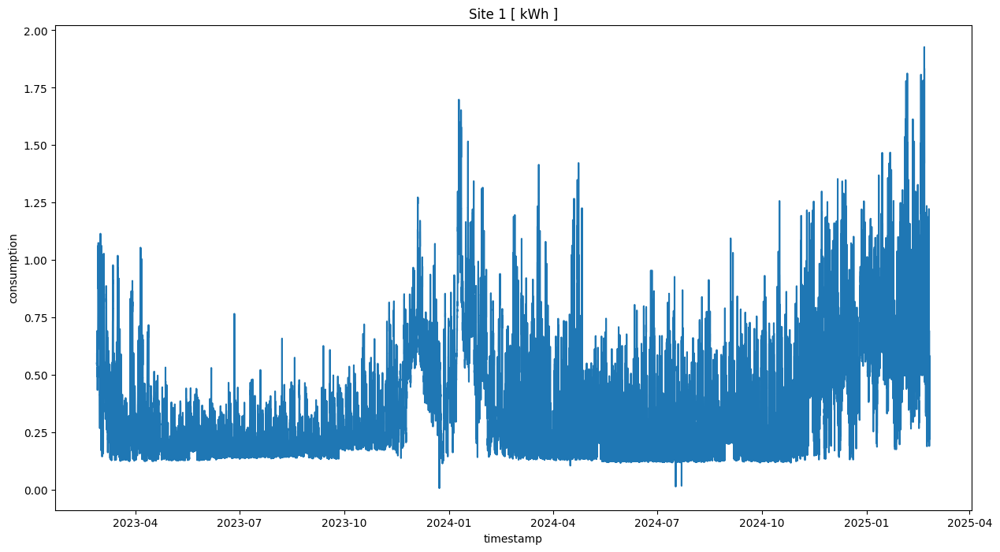

In [5]:
# Site #1 - has '[ kWh ]' column
df_site_1 = df[df['site_id'] == 1][['site_id', 'timestamp', '[ kWh ]']].reset_index(drop=True).copy()
df_site_1.rename(columns={'[ kWh ]': 'consumption'}, inplace=True)
sns.lineplot(data=df_site_1, x='timestamp', y='consumption')
plt.title('Site 1 [ kWh ]');

Site #2

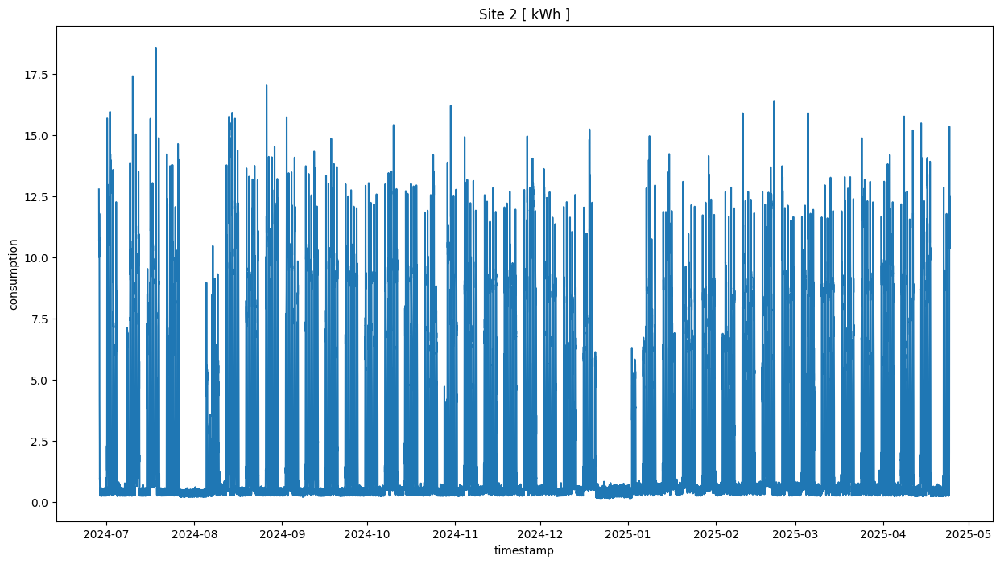

In [6]:
# Site #2 - has '[ kWh ]' column
df_site_2 = df[df['site_id'] == 2][['site_id', 'timestamp', '[ kWh ]']].reset_index(drop=True).copy()
df_site_2.rename(columns={'[ kWh ]': 'consumption'}, inplace=True)
sns.lineplot(data=df_site_2, x='timestamp', y='consumption')
plt.title('Site 2 [ kWh ]');

Site #3

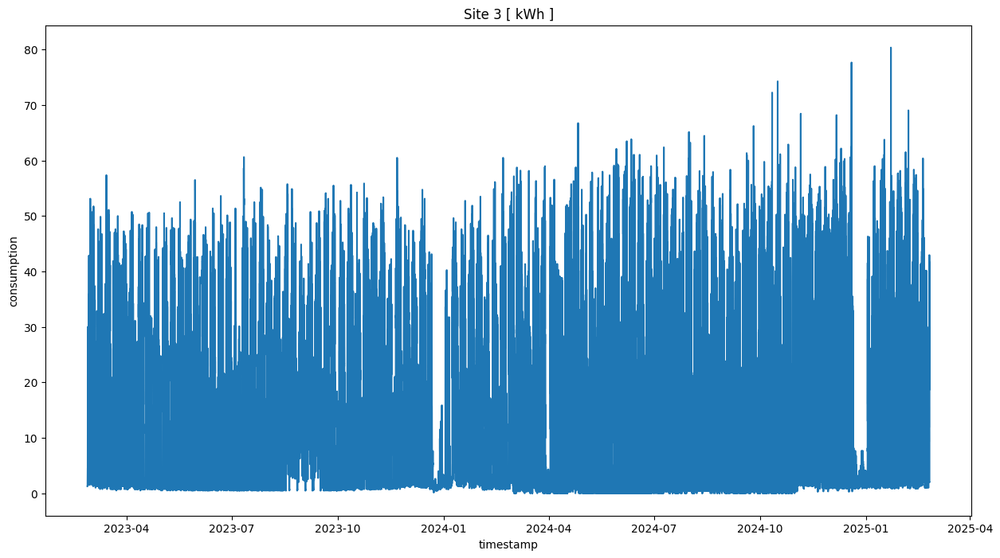

In [7]:
# Site #3 - has '[ kWh ]' column
df_site_3 = df[df['site_id'] == 3][['site_id', 'timestamp', '[ kWh ]']].reset_index(drop=True).copy()
df_site_3.rename(columns={'[ kWh ]': 'consumption'}, inplace=True)
sns.lineplot(data=df_site_3, x='timestamp', y='consumption')
plt.title('Site 3 [ kWh ]');

Site #4

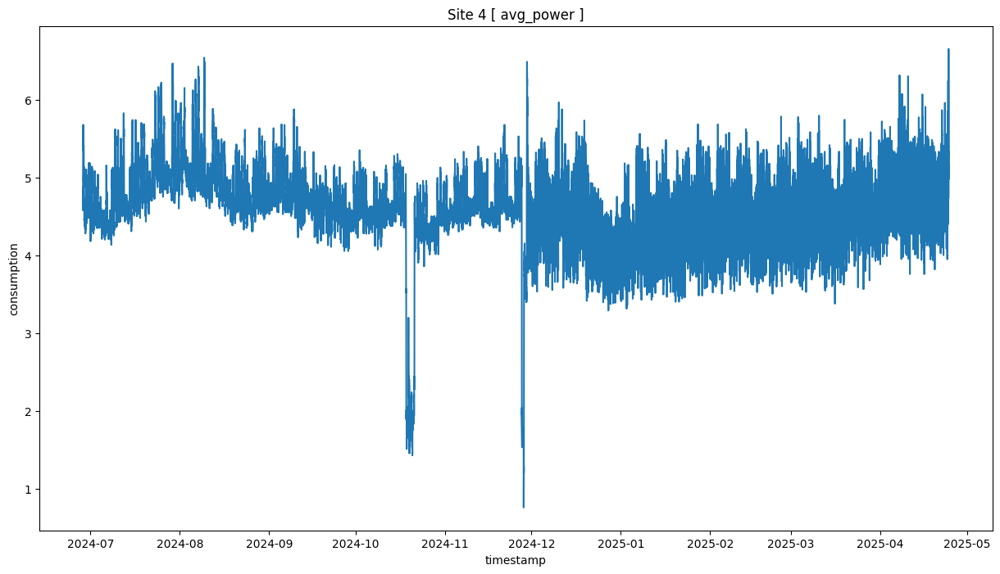

In [8]:
# Site #4 - has 'avg_power' column
df_site_4 = df[df['site_id'] == 4][['site_id', 'timestamp', 'avg_power', 'min', 'max']].reset_index(drop=True).copy()
df_site_4.rename(columns={'avg_power': 'consumption'}, inplace=True)
sns.lineplot(data=df_site_4, x='timestamp', y='consumption')
plt.title('Site 4 [ avg_power ]');

Site #5

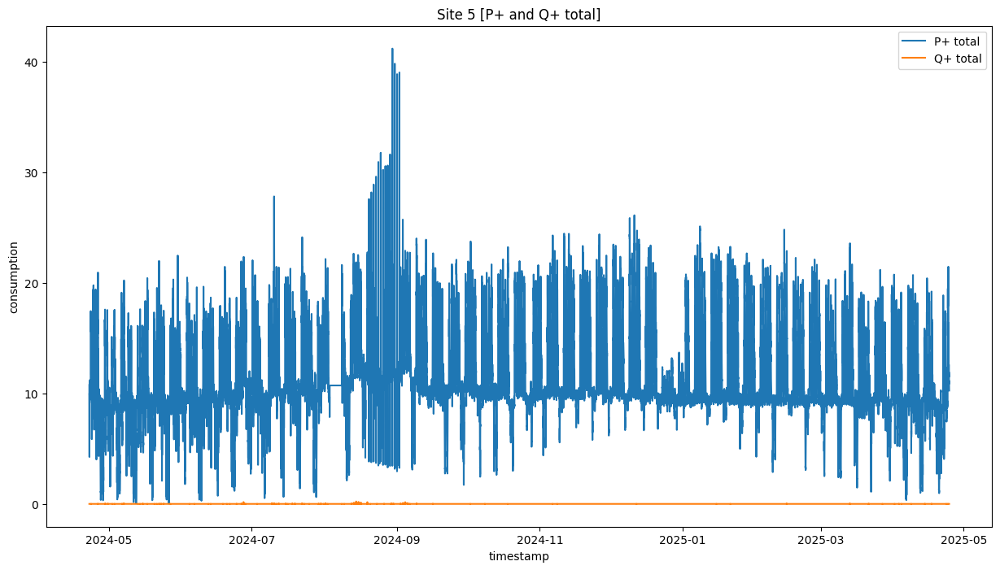

In [9]:
# Site #5 - has 'P+ total' and 'Q+ total' columns
df_site_5 = df[df['site_id'] == 5][['site_id', 'timestamp', 'P+ total', 'Q+ total']].reset_index(drop=True).copy()
df_site_5.rename(columns={'P+ total': 'consumption'}, inplace=True)
sns.lineplot(data=df_site_5, x='timestamp', y='consumption', label='P+ total')
sns.lineplot(data=df_site_5, x='timestamp', y='Q+ total', label='Q+ total')
plt.title('Site 5 [P+ and Q+ total]');

Site #6

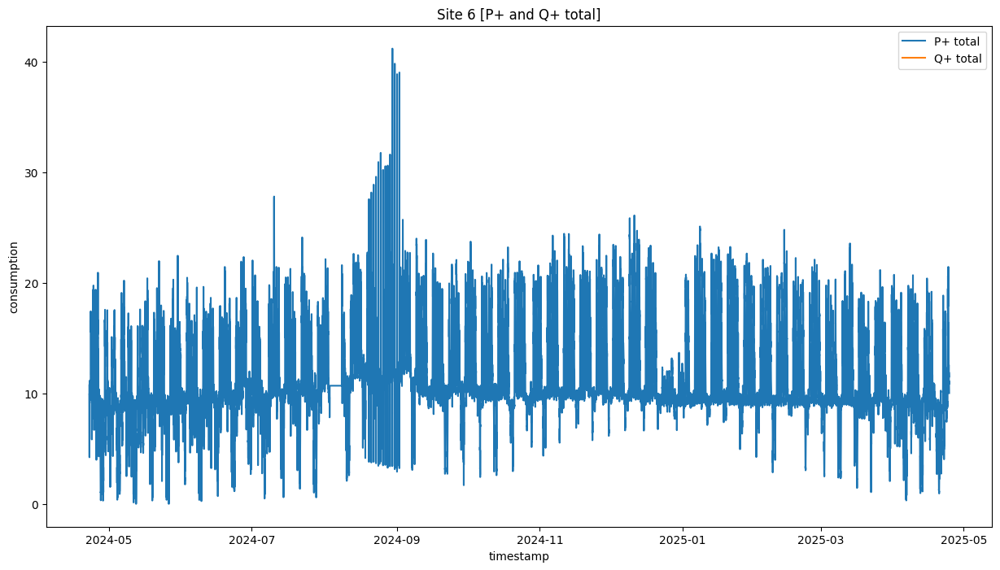

In [10]:
# Site #6 - has 'P+ total' and 'Q+ total' columns
df_site_6 = df[df['site_id'] == 6][['site_id', 'timestamp', 'P+ total', 'Q+ total']].reset_index(drop=True).copy()
df_site_6.rename(columns={'P+ total': 'consumption'}, inplace=True)
sns.lineplot(data=df_site_6, x='timestamp', y='consumption', label='P+ total')
sns.lineplot(data=df_site_6, x='timestamp', y='Q+ total', label='Q+ total')
plt.title('Site 6 [P+ and Q+ total]');

Site #7

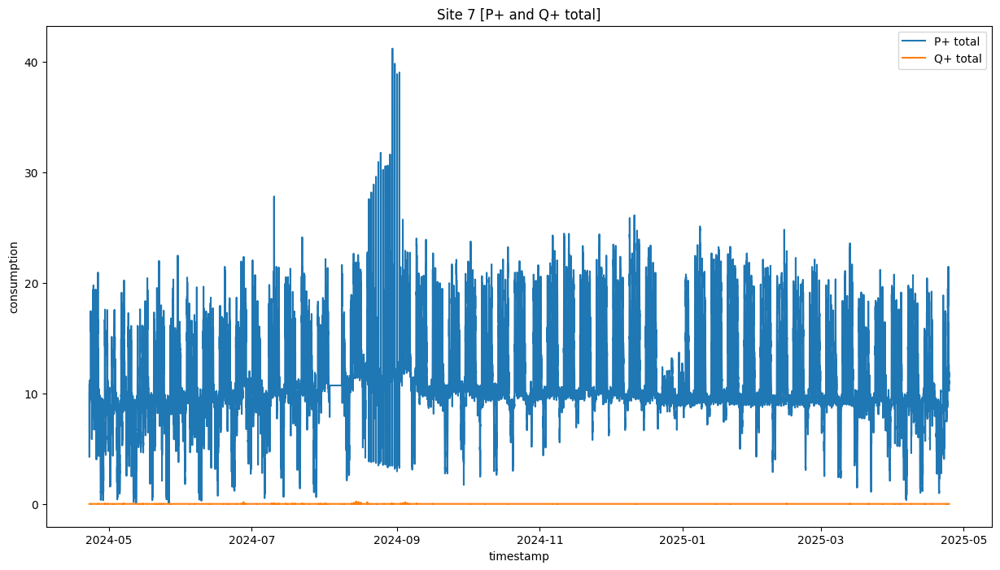

In [11]:
# Site #7 - has 'P+ total' and 'Q+ total' columns
df_site_7 = df[df['site_id'] == 7][['site_id', 'timestamp', 'P+ total', 'Q+ total']].reset_index(drop=True).copy()
df_site_7.rename(columns={'P+ total': 'consumption'}, inplace=True)
sns.lineplot(data=df_site_7, x='timestamp', y='consumption', label='P+ total')
sns.lineplot(data=df_site_7, x='timestamp', y='Q+ total', label='Q+ total')
plt.title('Site 7 [P+ and Q+ total]');

### Sites #5, #6 and #7 are `99.9%` similar

In [12]:
pd.concat([
    df_site_5['consumption'].describe().rename('Site 5'),
    df_site_6['consumption'].describe().rename('Site 6'),
    df_site_7['consumption'].describe().rename('Site 7')
], axis=1)

,Site 5,Site 6,Site 7
count,35255.000000,35256.000000,35255.000000
mean,11.491664,11.491622,11.491664
std,3.924028,3.923980,3.924028
min,0.031771,0.031771,0.031771
25%,9.296745,9.296810,9.296745
50%,10.312500,10.312500,10.312500
75%,13.669651,13.669321,13.669651
max,41.160156,41.160156,41.160156


In [13]:
df_site_5['consumption'].shape, df_site_6['consumption'].shape, df_site_7['consumption'].shape

((35255,), (35256,), (35255,))

In [14]:
df_site_5['consumption'].iloc[-1], df_site_6['consumption'].iloc[-1]

(np.float64(10.24375), np.float64(10.0375))

Site #5 and Site #6 are 100% the same

In [15]:
df_site_5['consumption'].eq(df_site_6['consumption']).sum()/ df_site_5['consumption'].shape[0]

np.float64(1.0)

Site #5 and Site #7 are 99.9% the same

In [16]:
df_site_5['consumption'].eq(df_site_7['consumption']).sum()/ df_site_5['consumption'].shape[0]

np.float64(1.0)

Site #7 data has a 15-minutes offset compared to Site #5 and Site #6

In [17]:
display(df_site_5.iloc[:5])
display(df_site_6.iloc[:5])
df_site_7.iloc[:5]

,site_id,timestamp,consumption,Q+ total
0,5,2024-04-22 14:45:00,10.753027,0.0
1,5,2024-04-22 15:00:00,9.298470,0.0
2,5,2024-04-22 15:15:00,10.181670,0.0
3,5,2024-04-22 15:30:00,8.434020,0.0
4,5,2024-04-22 15:45:00,7.439453,0.0


,site_id,timestamp,consumption,Q+ total
0,6,2024-04-22 14:45:00,10.753027,NaN
1,6,2024-04-22 15:00:00,9.298470,NaN
2,6,2024-04-22 15:15:00,10.181670,NaN
3,6,2024-04-22 15:30:00,8.434020,NaN
4,6,2024-04-22 15:45:00,7.439453,NaN


,site_id,timestamp,consumption,Q+ total
0,7,2024-04-22 15:00:00,10.753027,0.0
1,7,2024-04-22 15:15:00,9.298470,0.0
2,7,2024-04-22 15:30:00,10.181670,0.0
3,7,2024-04-22 15:45:00,8.434020,0.0
4,7,2024-04-22 16:00:00,7.439453,0.0


Values in Sites #5 and #7 that are not the same. It looks like Site #7 now has an index -1 offset (not timestamp) because of transition to winter time and confusion in the database

In [18]:
non_equal_ts_5_vs_7 = df_site_5.loc[~df_site_5['consumption'].eq(df_site_7['consumption'])].index#['timestamp'].unique()
display(df_site_5.loc[non_equal_ts_5_vs_7][['timestamp', 'consumption']])
df_site_7.loc[non_equal_ts_5_vs_7][['timestamp', 'consumption']]
# display(df_site_5.loc[df_site_5['timestamp'].isin(non_equal_ts_5_vs_7)][['timestamp', 'consumption']])
# df_site_7.loc[df_site_7['timestamp'].isin(non_equal_ts_5_vs_7)][['timestamp', 'consumption']]


,timestamp,consumption


,timestamp,consumption


After that, they continue to be the same with a 15-minutes offset

In [19]:
display(df_site_5.loc[18004:18010][['timestamp', 'consumption']])
df_site_7.loc[18004:18010][['timestamp', 'consumption']]

,timestamp,consumption
18004,2024-10-27 02:45:00,9.100000
18005,2024-10-27 03:00:00,9.337500
18006,2024-10-27 03:15:00,9.415625
18007,2024-10-27 03:30:00,8.943750
18008,2024-10-27 03:45:00,9.312500
18009,2024-10-27 04:00:00,9.131250
18010,2024-10-27 04:15:00,9.393750


,timestamp,consumption
18004,2024-10-27 03:00:00,9.100000
18005,2024-10-27 03:15:00,9.337500
18006,2024-10-27 03:30:00,9.415625
18007,2024-10-27 03:45:00,8.943750
18008,2024-10-27 04:00:00,9.312500
18009,2024-10-27 04:15:00,9.131250
18010,2024-10-27 04:30:00,9.393750


Site #8

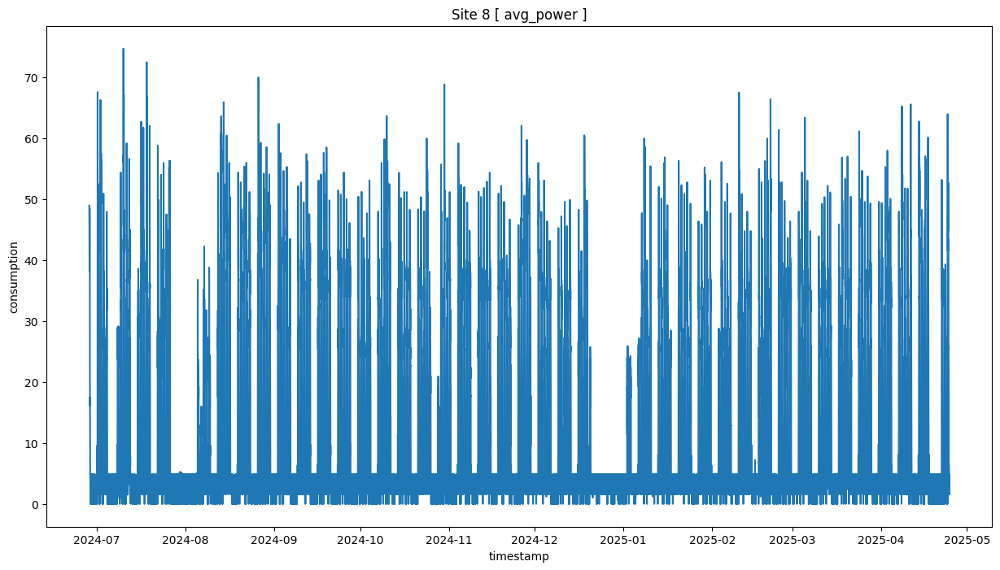

In [20]:
# Site #8 - has 'avg_power' column
df_site_8 = df[df['site_id'] == 8][['site_id', 'timestamp', 'avg_power', 'min', 'max']].reset_index(drop=True).copy()
df_site_8.rename(columns={'avg_power': 'consumption'}, inplace=True)
sns.lineplot(data=df_site_8, x='timestamp', y='consumption')
plt.title('Site 8 [ avg_power ]');

Site #9

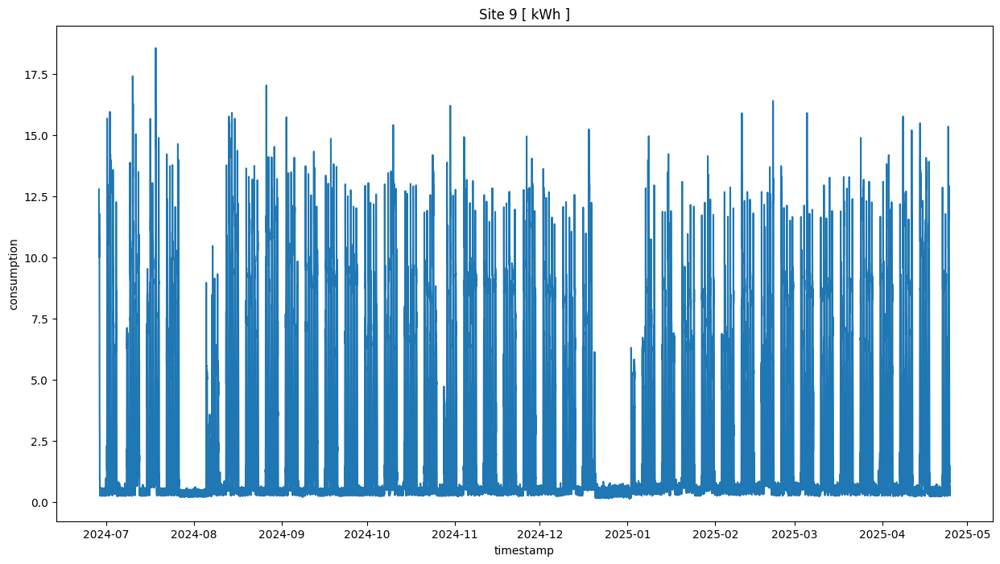

In [21]:
# Site #9 - has '[ kWh ]' column
df_site_9 = df[df['site_id'] == 9][['site_id', 'timestamp', '[ kWh ]']].reset_index(drop=True).copy()
df_site_9.rename(columns={'[ kWh ]': 'consumption'}, inplace=True)
sns.lineplot(data=df_site_9, x='timestamp', y='consumption')
plt.title('Site 9 [ kWh ]');

## Create list of sites

In [22]:
list_of_sites = [df_site_1, df_site_2, df_site_3, df_site_4, df_site_5, 
                 df_site_6, df_site_7, df_site_8, df_site_9]

## Peaks detection

In [23]:
from scipy.signal import find_peaks

def normalize_zscore(y):
    return (y - np.mean(y)) / np.std(y)

def robust_zscore(y):
    y = np.array(y)
    med = np.median(y)
    mad = np.median(np.abs(y - med))
    return (y - med) / (mad if mad > 1e-6 else 1)

def plot_spikes_and_drops(x, y, title="Signal with Spikes and Drops", prominence=1.0, robust=False):

    if robust:
        y_pred_norm = robust_zscore(y)
    else:
        y_pred_norm = normalize_zscore(y)
    peaks, _ = find_peaks(y_pred_norm, prominence=prominence)  # use normalized threshold
    drops, _ = find_peaks(-y_pred_norm, prominence=prominence)  # use normalized threshold

    plt.figure(figsize=(15, 9))
    plt.plot(x, y, label="Signal", color="gray")
    plt.plot(x[peaks], y[peaks], "r^", label="Spikes")
    plt.plot(x[drops], y[drops], "bv", label="Drops")
    plt.title(title)
    plt.xlabel("Time")
    plt.ylabel("Value")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

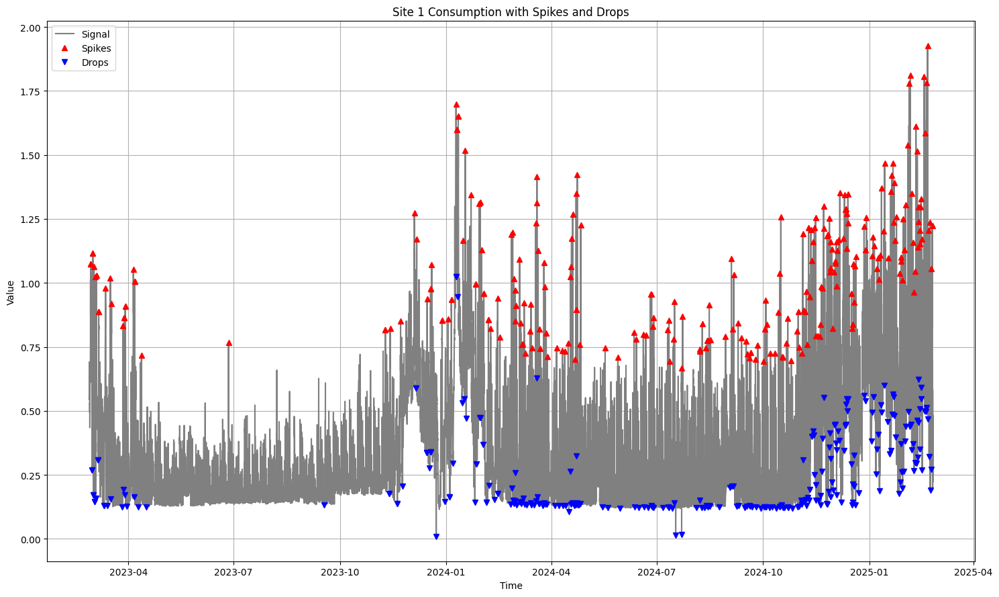

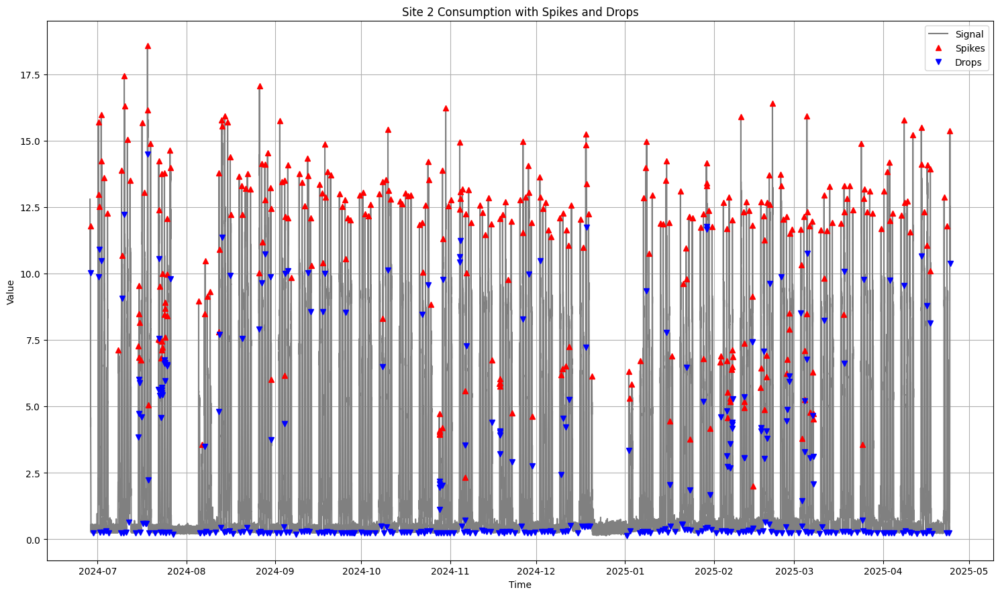

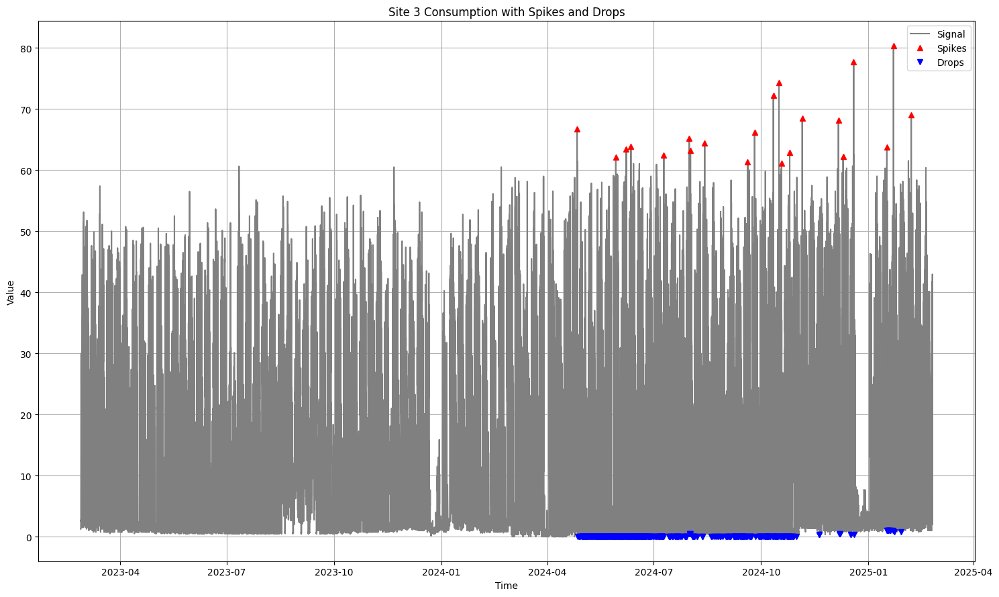

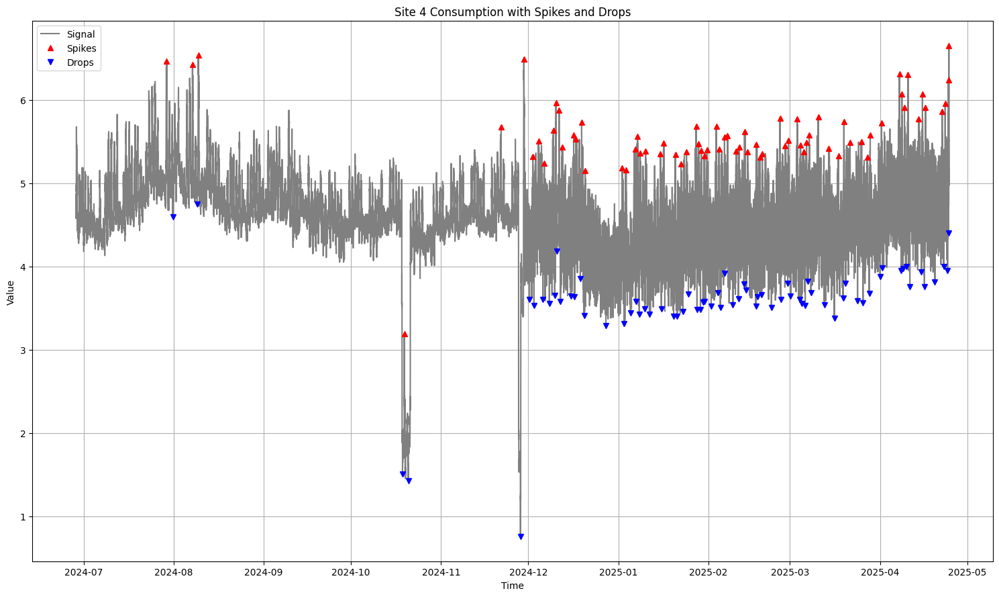

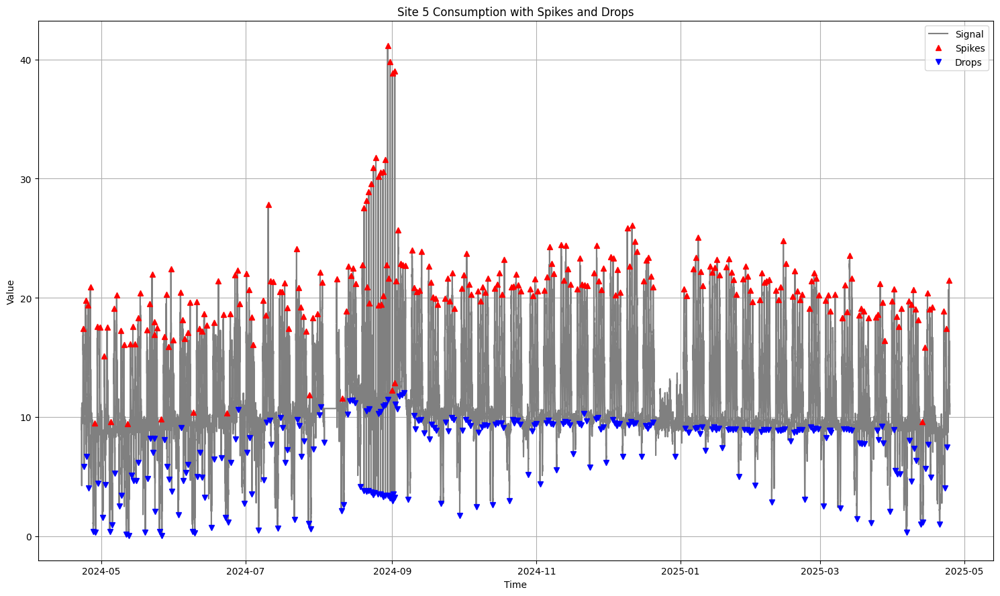

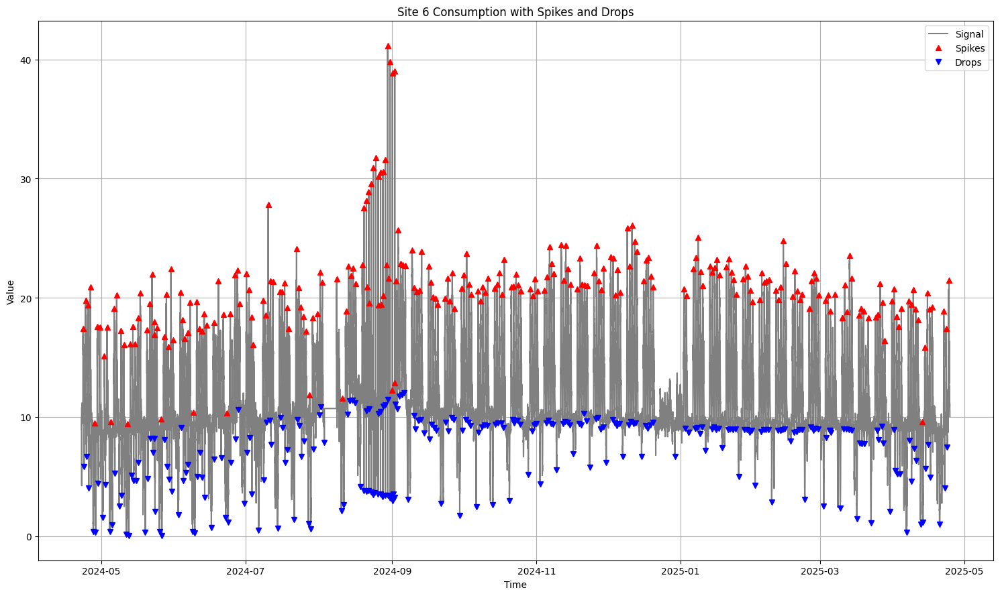

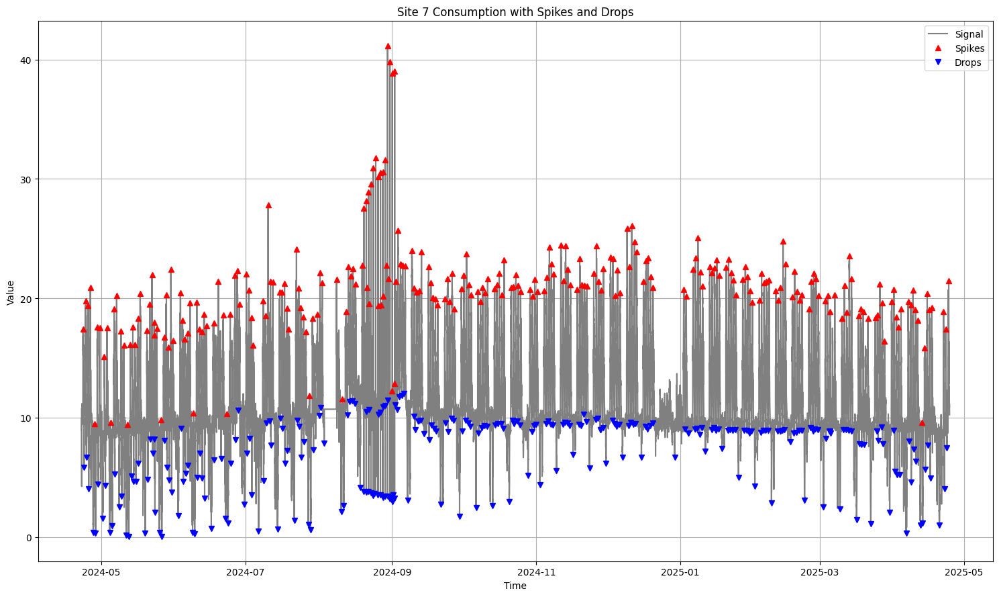

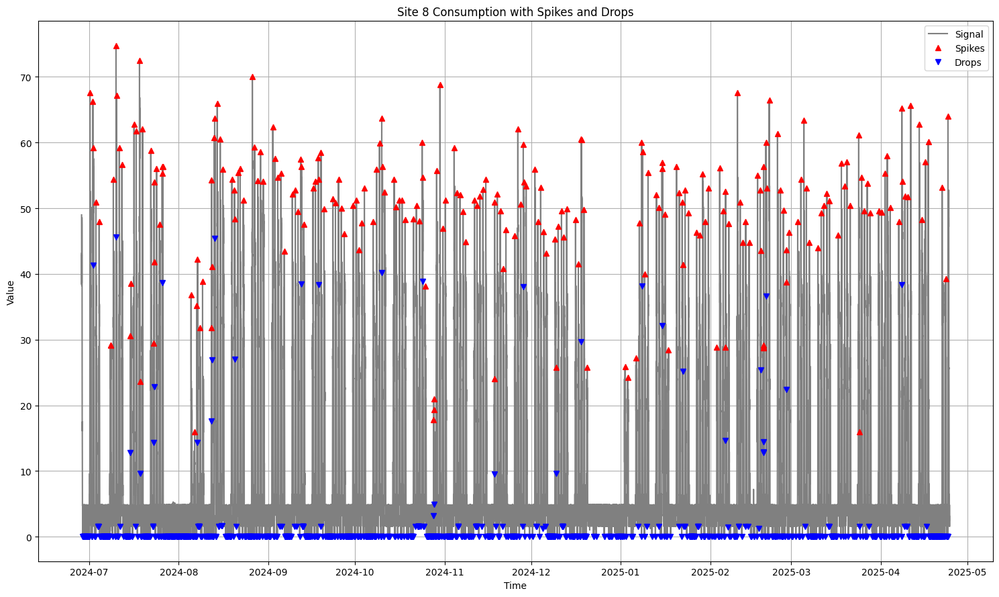

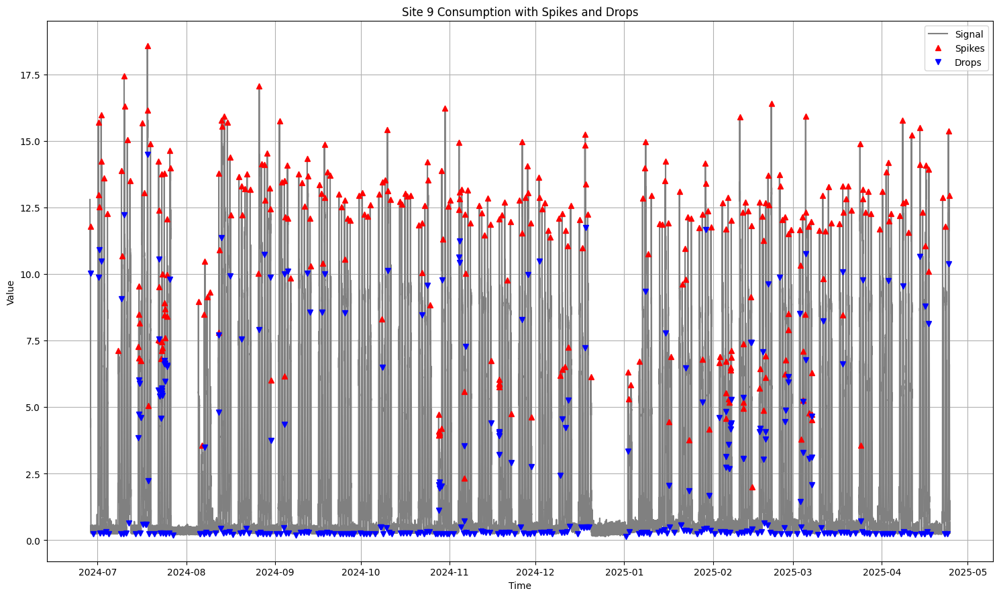

In [ ]:
for i, site_df in enumerate(list_of_sites, 1):
    plot_spikes_and_drops(site_df['timestamp'],
                        site_df['consumption'], 
                        title=f"Site {i} Consumption with Spikes and Drops",
                        prominence=5.0, robust=True)

## Hourly Analysis by Site

In [37]:
def create_hourly_analysis_for_site(site_df, site_id):
    """Create hourly aggregated data for a specific site"""
    # Group by hour
    site_hour = site_df.groupby(site_df['timestamp'].dt.floor('h'))
    
    # Create index for full time range of this site
    full_range = pd.DataFrame(
        index=pd.date_range(
            site_df['timestamp'].min().floor('h'),
            site_df['timestamp'].max().floor('h'), 
            freq='h'
        )
    )
    
    # Join with hourly aggregated consumption data
    consumption_hour = full_range.join(site_hour['consumption'].mean(), how='left').squeeze()
    
    return consumption_hour

In [38]:
# Create hourly data for each site
site_hourly_data = {}
for i, site_df in enumerate(list_of_sites, 1):
    site_hourly_data[f'site_{i}'] = create_hourly_analysis_for_site(site_df, i)
    print(f"Site {i} hourly data shape: {site_hourly_data[f'site_{i}'].shape}")

Site 1 hourly data shape: (17519,)
Site 2 hourly data shape: (7202,)
Site 3 hourly data shape: (17519,)
Site 4 hourly data shape: (7212,)
Site 5 hourly data shape: (8815,)
Site 6 hourly data shape: (8815,)
Site 7 hourly data shape: (8814,)
Site 8 hourly data shape: (7212,)
Site 9 hourly data shape: (7212,)


In [39]:
# Collect statistics for each site's hourly data into a single DataFrame
stats_list = []
for i in range(1, len(site_hourly_data.keys())+1):
    site_key = f'site_{i}'
    if site_key in site_hourly_data:
        stats = site_hourly_data[site_key].describe()
        stats.name = f'Site {i}'
        stats_list.append(stats)

pd.concat(stats_list, axis=1)

,Site 1,Site 2,Site 3,Site 4,Site 5,Site 6,Site 7,Site 8,Site 9
count,17519.000000,7201.000000,17519.000000,7209.000000,8814.000000,8814.000000,8813.000000,7209.000000,7211.000000
mean,0.341821,2.647835,15.351291,4.602493,11.491790,11.491770,11.491886,11.461818,2.651573
std,0.233068,3.650415,14.455698,0.478657,3.831241,3.831246,3.833864,14.102376,3.654078
min,0.008750,0.206890,0.125000,0.949086,0.662380,0.662380,0.364844,0.600000,0.206890
25%,0.165000,0.371225,1.250000,4.376929,9.330769,9.330769,9.320312,2.800000,0.371264
50%,0.245000,0.458644,12.125000,4.588570,10.304408,10.304408,10.298438,3.600000,0.458943
75%,0.463000,4.803200,27.500000,4.866046,13.703119,13.703119,13.767318,19.294409,4.827935
max,1.771500,15.722588,62.250000,6.433867,26.833203,26.833203,26.044922,63.519838,15.722588


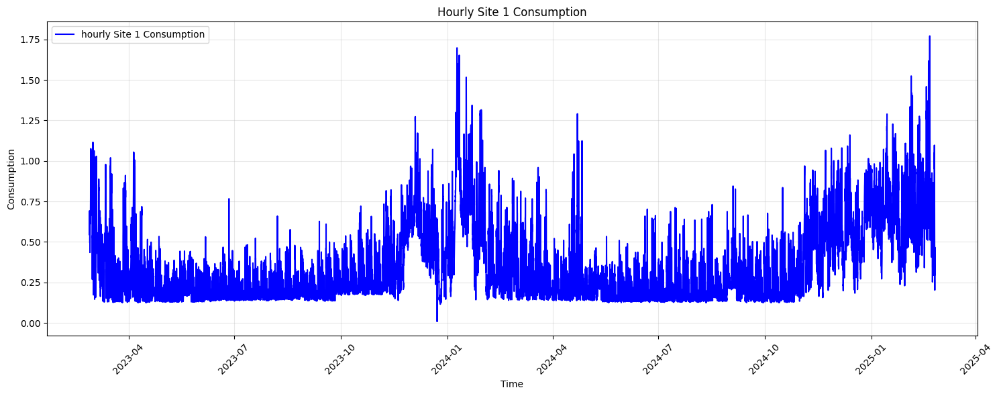

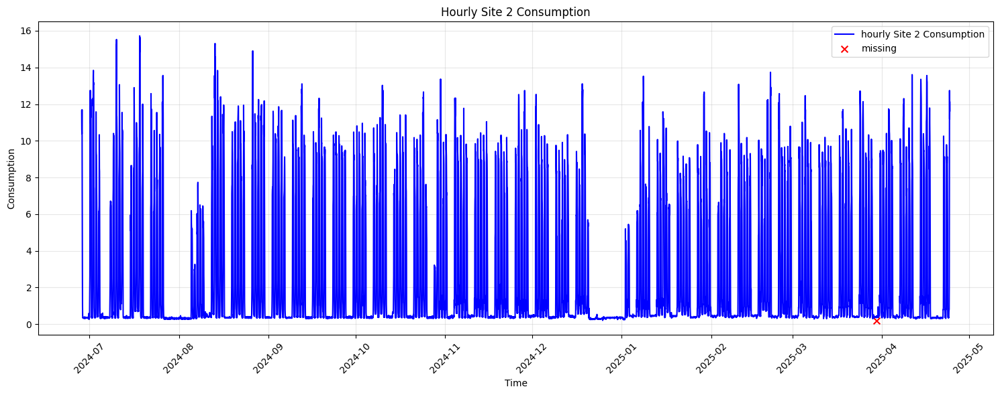

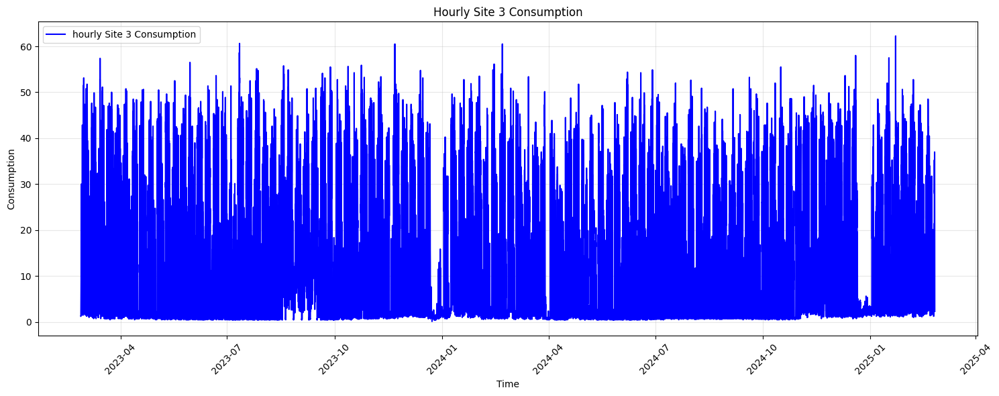

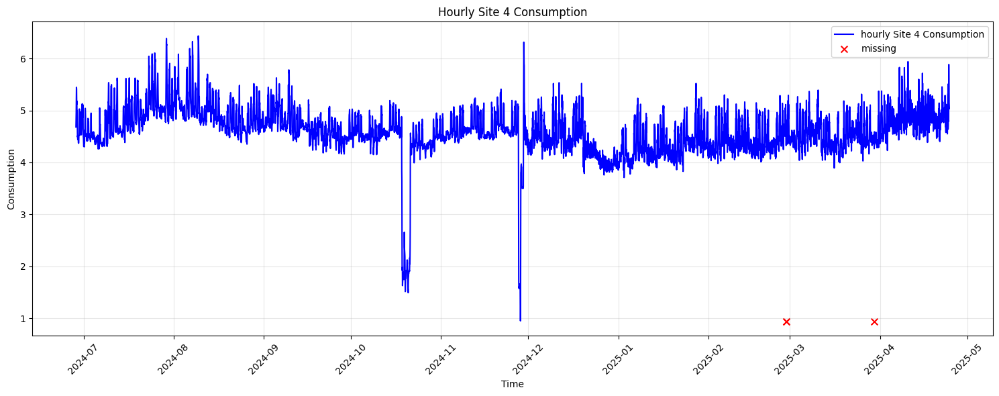

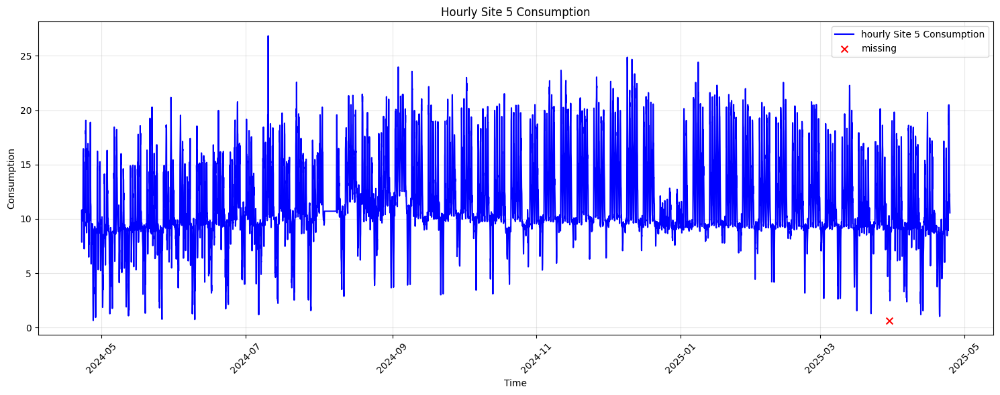

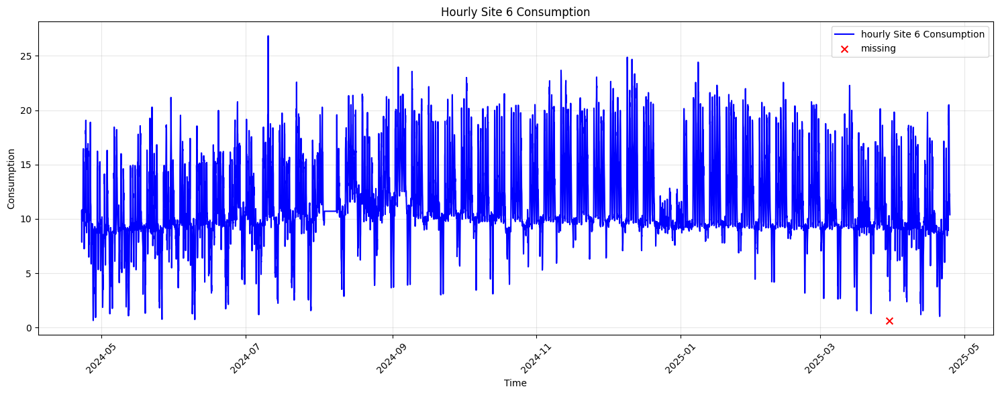

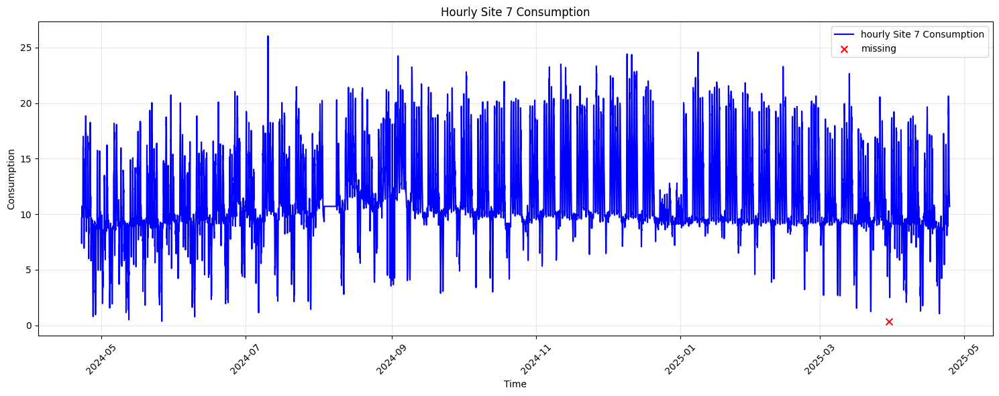

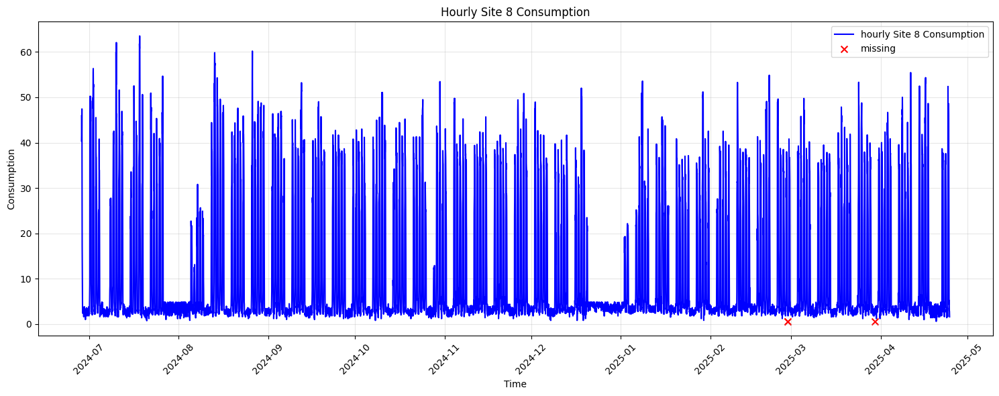

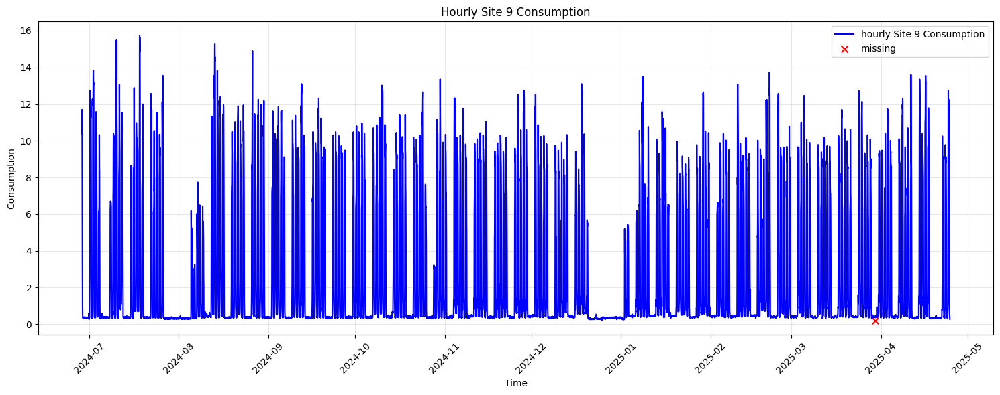

In [40]:
def plot_hourly_data(series, title, color='blue'):
    """Plot hourly data with missing values marked"""
    # Choose a sensible default value for missing data
    fill_value = series.median() if not pd.isna(series.median()) else 0
    
    plt.figure(figsize=(15, 6))
    sns.lineplot(x=series.index, y=series.fillna(fill_value), label=f'hourly {title}', color=color)
    
    # Mark missing values
    if series.isna().any():
        missing_mask = series.isna()
        plt.scatter(
            x=series[missing_mask].index,
            y=[series.min()-0.01]*series[missing_mask].shape[0],
            color='red',
            marker='x',
            label='missing',
            s=50
        )
    
    plt.title(f"Hourly {title}")
    plt.xlabel("Time")
    plt.ylabel("Consumption")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# Plot hourly data for each site
for i in range(1, len(site_hourly_data.keys())+1):
    site_key = f'site_{i}'
    if site_key in site_hourly_data:
        plot_hourly_data(site_hourly_data[site_key], f'Site {i} Consumption')

### Detect peaks in hourly consumption

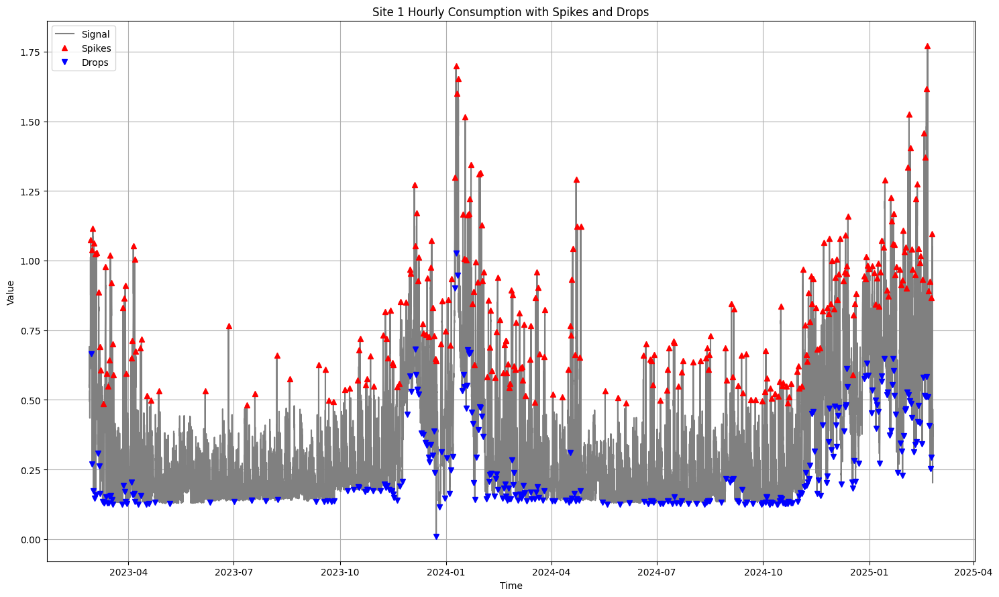

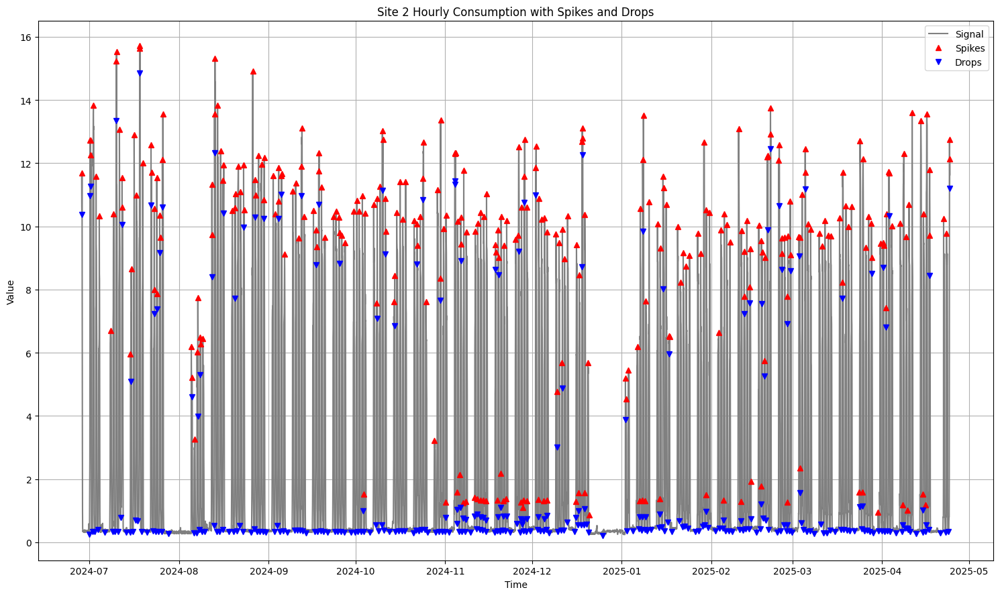

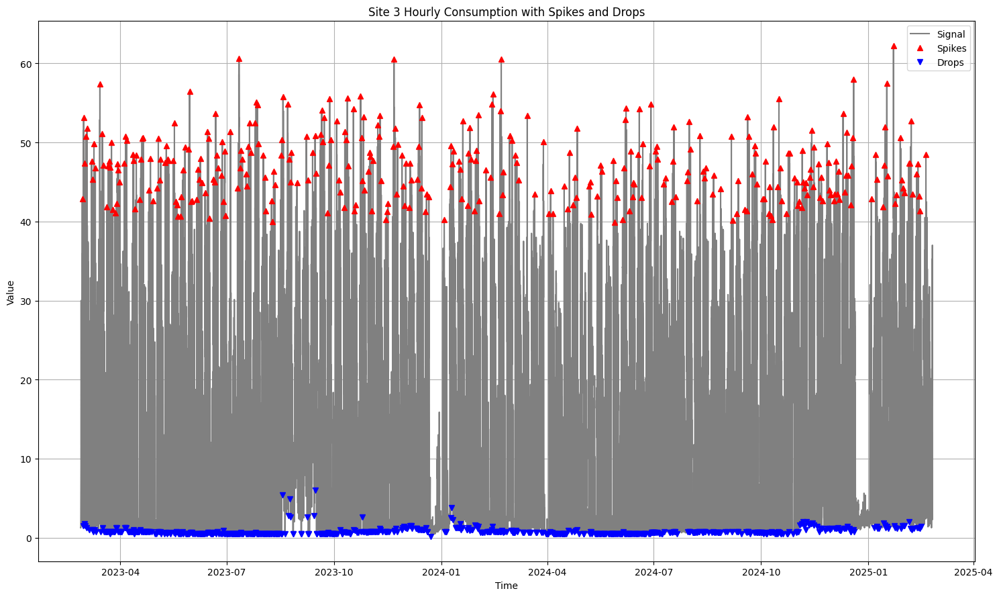

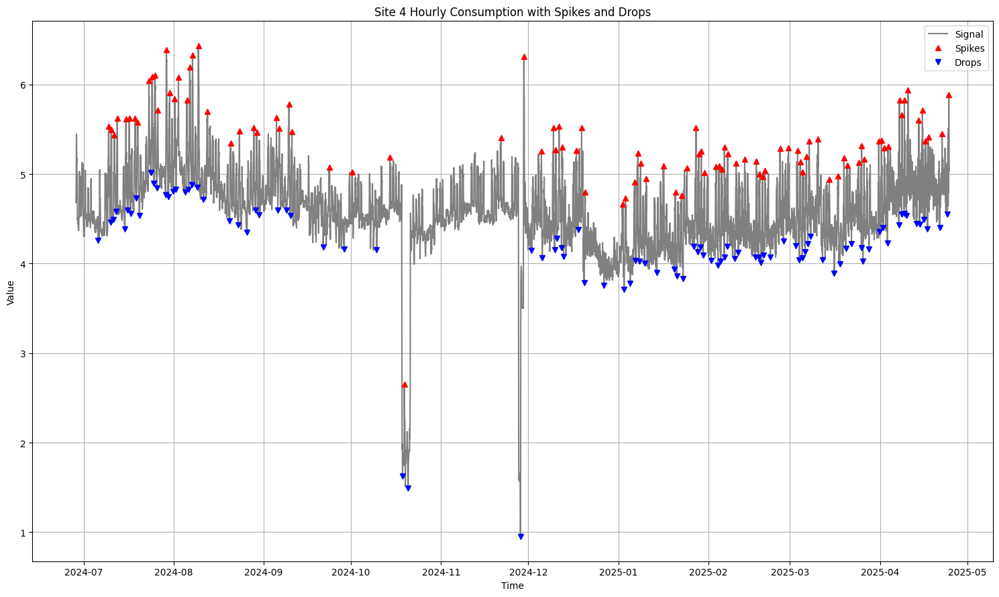

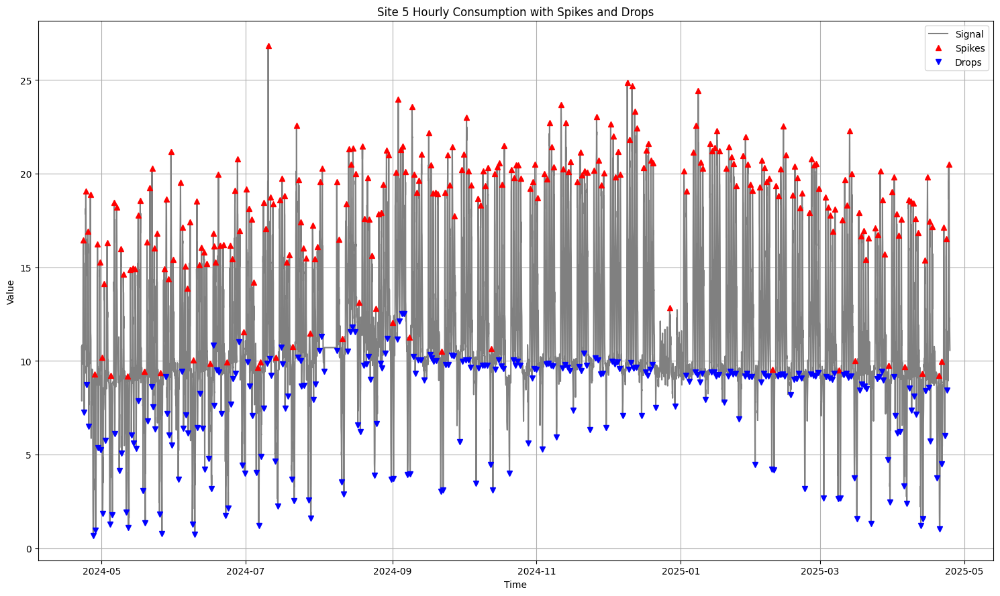

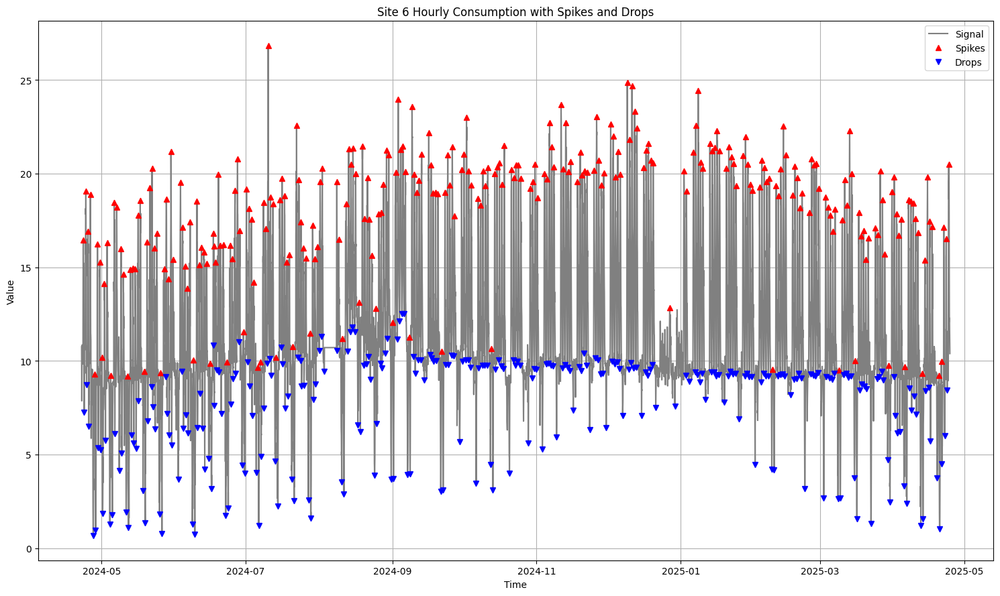

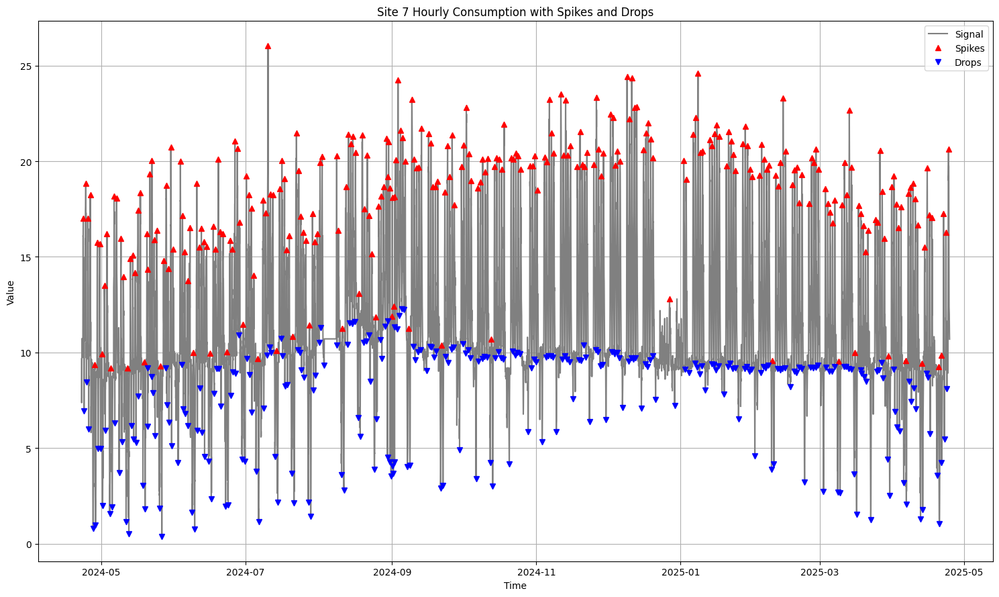

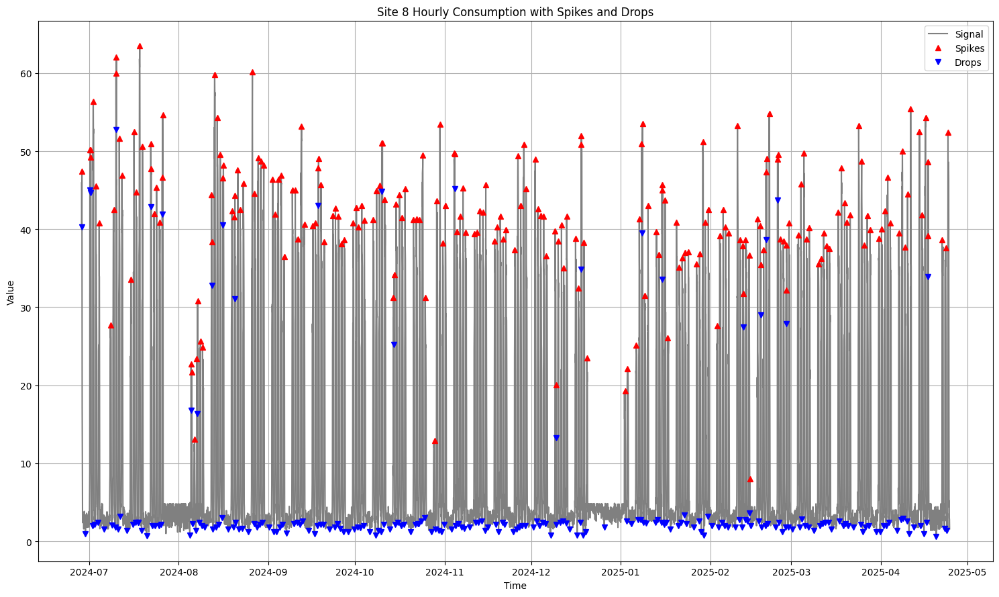

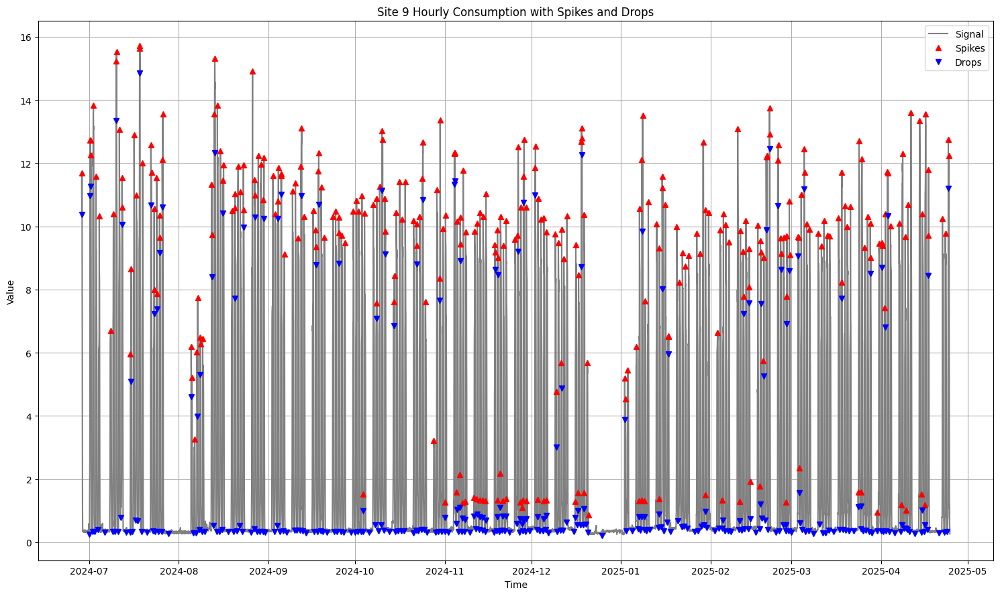

In [43]:
# Detect peaks in hourly consumption for each site
for i in range(1, len(site_hourly_data.keys())+1):
    site_key = f'site_{i}'
    if site_key in site_hourly_data:
        hourly_data = site_hourly_data[site_key].dropna()
        if len(hourly_data) > 0:
            plot_spikes_and_drops(
                hourly_data.index,
                hourly_data.values, 
                title=f"Site {i} Hourly Consumption with Spikes and Drops",
                prominence=3.5, robust=True
            )

## Weekly Patterns Analysis by Site


Analyzing weekly patterns for Site 1:


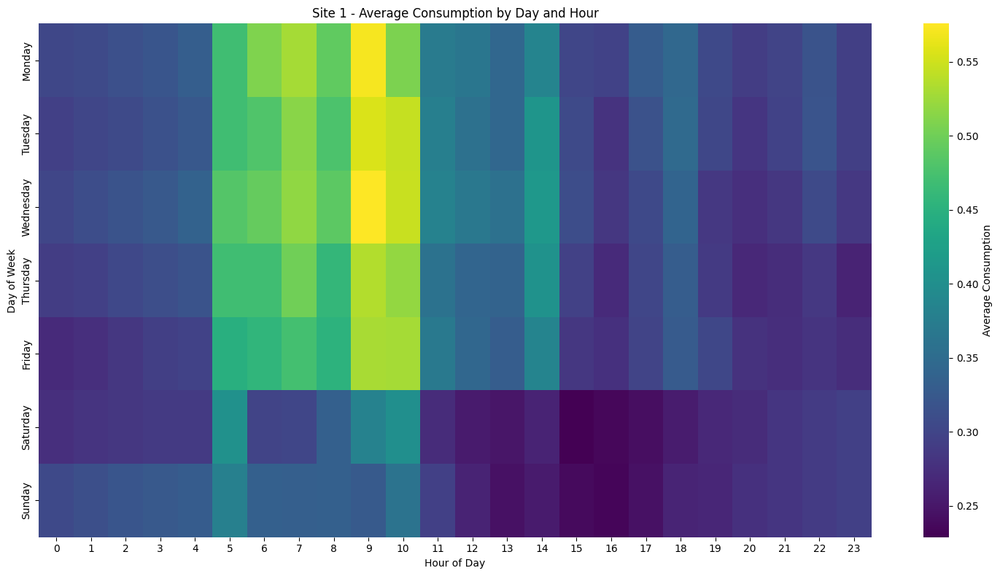


Analyzing weekly patterns for Site 2:


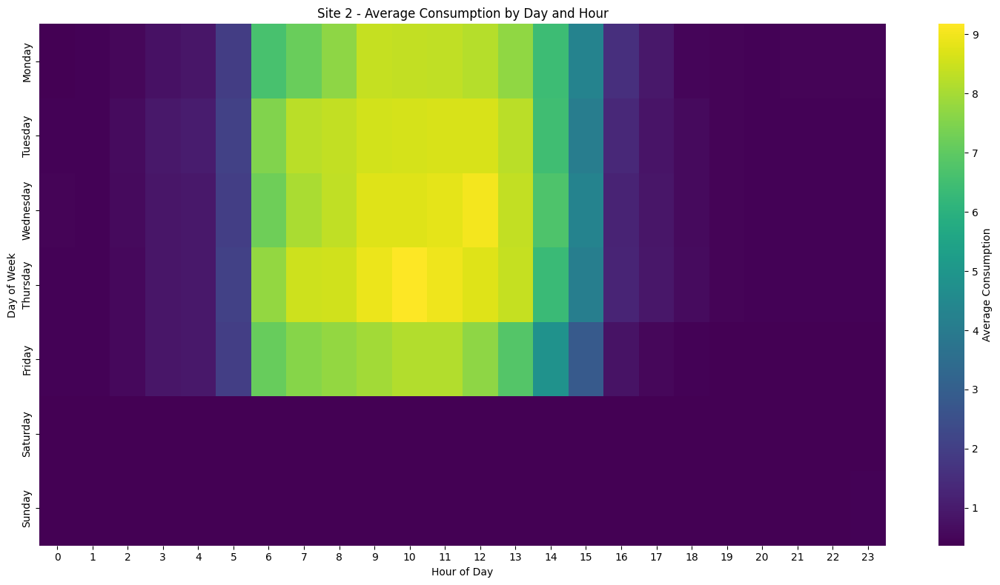


Analyzing weekly patterns for Site 3:


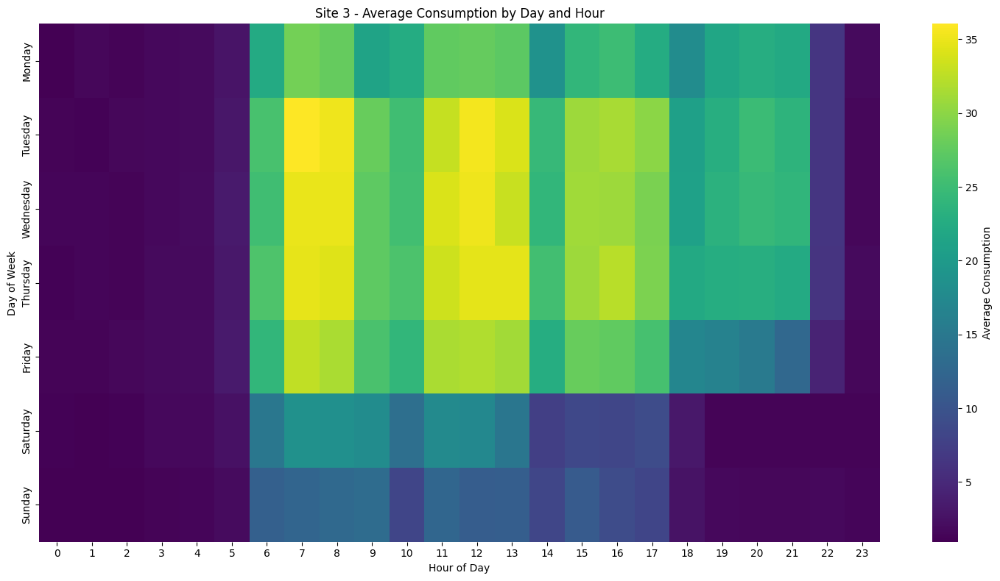


Analyzing weekly patterns for Site 4:


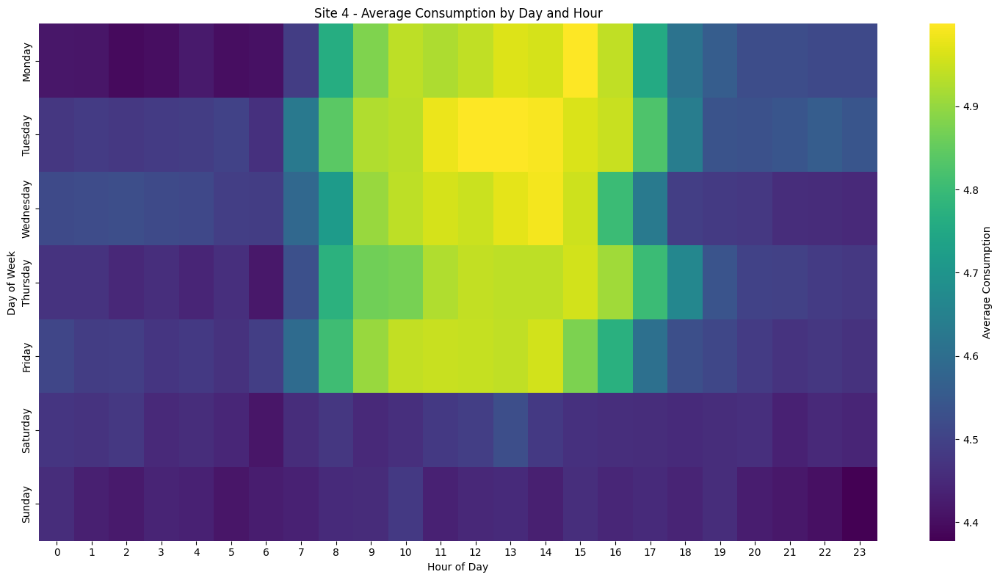


Analyzing weekly patterns for Site 5:


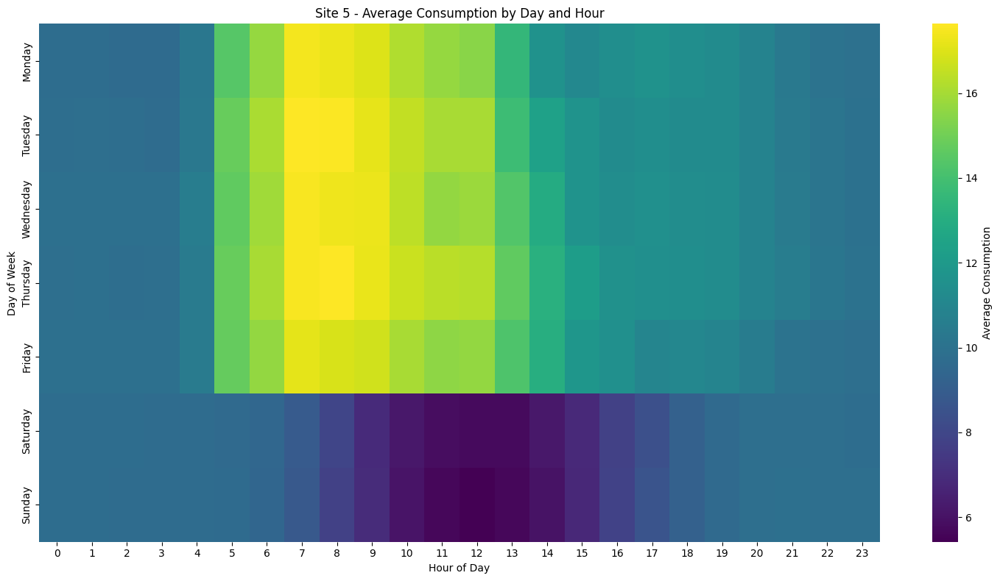


Analyzing weekly patterns for Site 6:


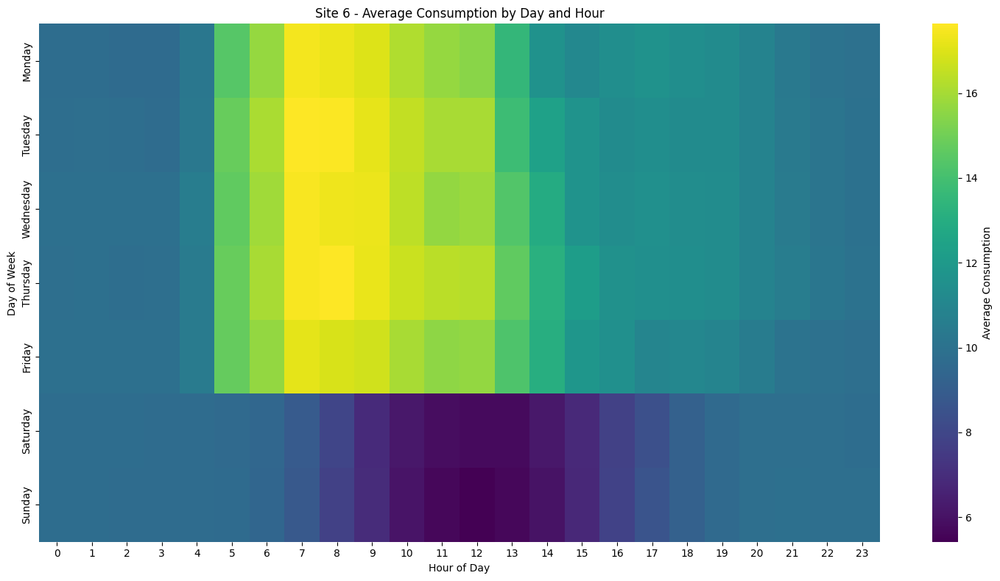


Analyzing weekly patterns for Site 7:


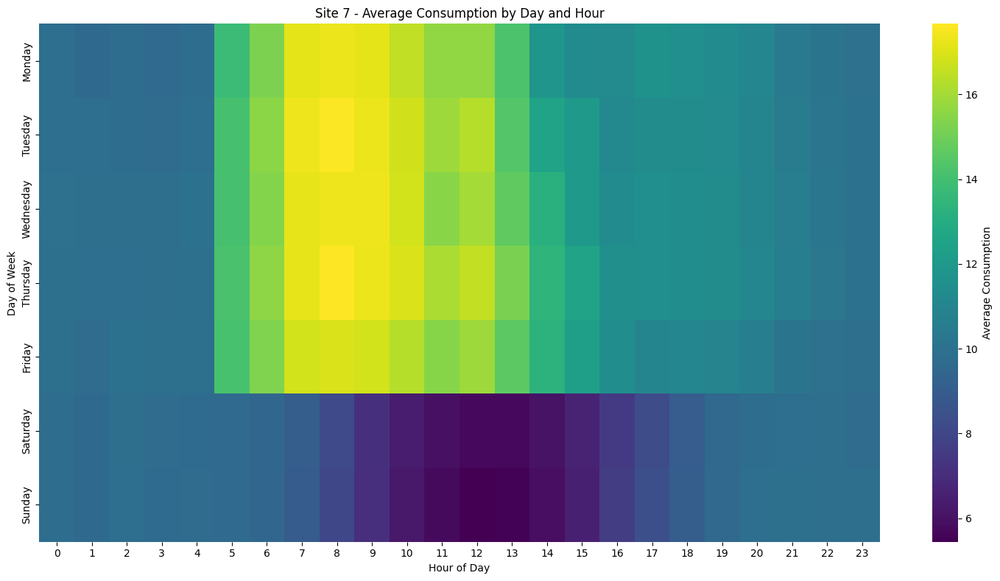


Analyzing weekly patterns for Site 8:


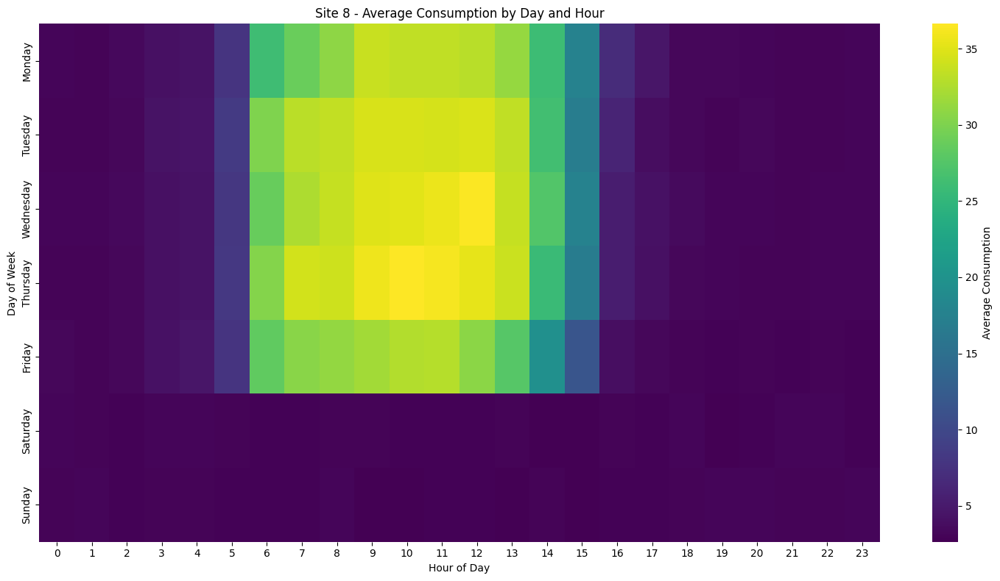


Analyzing weekly patterns for Site 9:


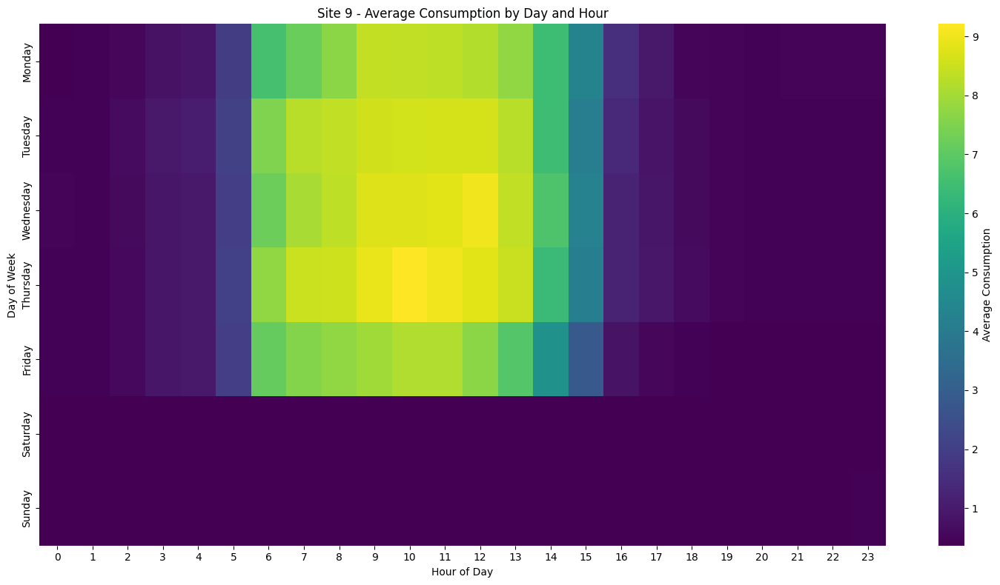

In [42]:
def analyze_weekly_patterns_for_site(df, site_id):
    """Analyze weekly patterns for a specific site"""
    # Extract day of week and hour
    df['day_of_week'] = df['timestamp'].dt.day_name()
    df['hour'] = df['timestamp'].dt.hour

    # Group by day of week and hour
    daily_patterns = df.groupby(['day_of_week', 'hour']).agg({
        'consumption': 'mean'
    }).reset_index()

    # Order days correctly
    day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
    daily_patterns['day_of_week'] = pd.Categorical(daily_patterns['day_of_week'], categories=day_order, ordered=True)
    daily_patterns = daily_patterns.sort_values(['day_of_week', 'hour'])

    # Create pivot table for heatmap
    pivot_table = daily_patterns.pivot(index='day_of_week', columns='hour', values='consumption')

    # Plot heatmap
    plt.figure(figsize=(15, 8))
    sns.heatmap(pivot_table, cmap='viridis', annot=False, cbar_kws={'label': 'Average Consumption'})
    plt.title(f'Site {site_id} - Average Consumption by Day and Hour')
    plt.xlabel('Hour of Day')
    plt.ylabel('Day of Week')
    plt.tight_layout()
    plt.show()

    return daily_patterns, pivot_table

# Analyze weekly patterns for each site
weekly_patterns = {}
for i, site_df in enumerate(list_of_sites, 1):
    print(f"\nAnalyzing weekly patterns for Site {i}:")
    patterns, pivot = analyze_weekly_patterns_for_site(site_df, i)
    weekly_patterns[f'site_{i}'] = {'patterns': patterns, 'pivot': pivot}

## Autocorrelation Analysis by Site


Autocorrelation Analysis for Site 1:


<Figure size 1500x600 with 0 Axes>

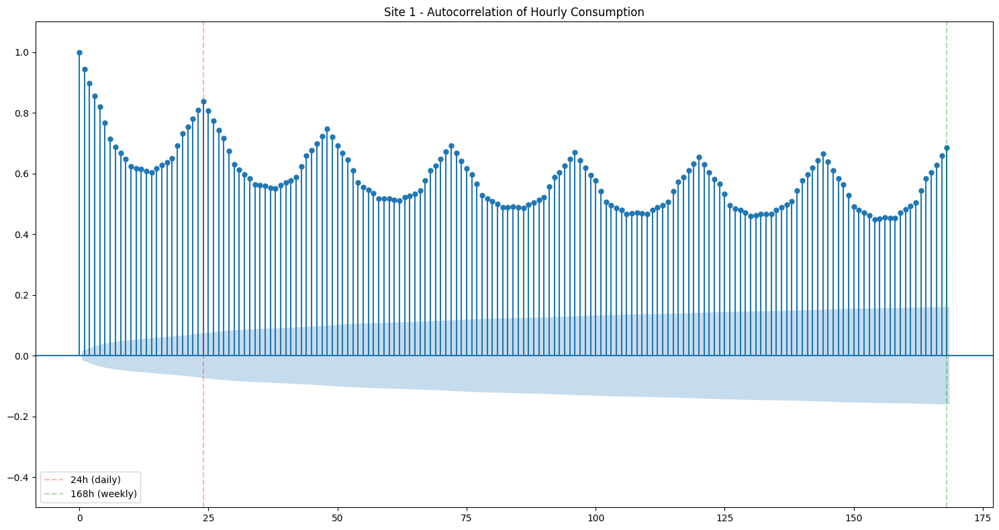

Site 1 - Top 7 ACF lags (abs ranking):
  Lag 1: +0.945
  Lag 2: +0.896
  Lag 3: +0.856
  Lag 24: +0.837
  Lag 4: +0.820
  Lag 23: +0.810
  Lag 25: +0.806


<Figure size 1500x600 with 0 Axes>

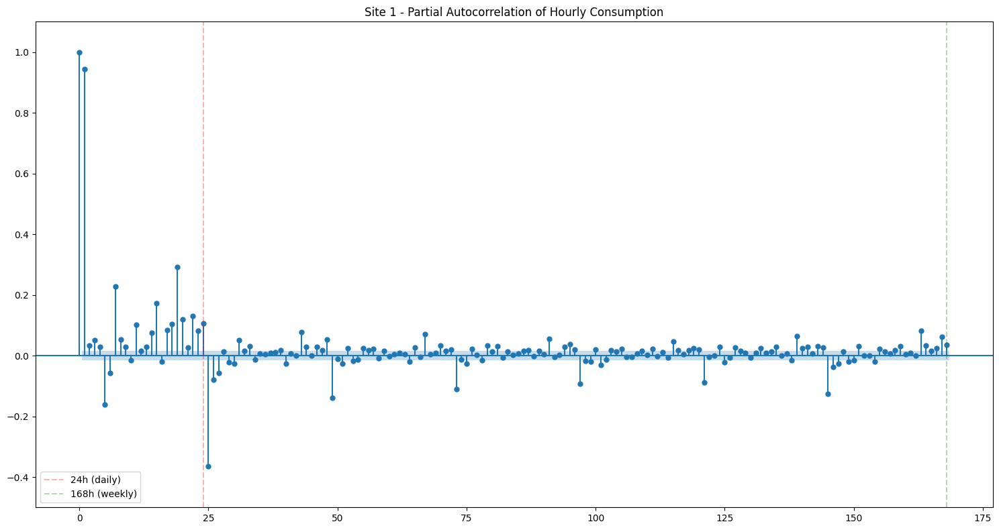

Site 1 - Top 7 PACF lags (abs ranking):
  Lag 1: +0.945
  Lag 25: -0.365
  Lag 19: +0.292
  Lag 7: +0.228
  Lag 15: +0.173
  Lag 5: -0.161
  Lag 49: -0.139

Autocorrelation Analysis for Site 2:


<Figure size 1500x600 with 0 Axes>

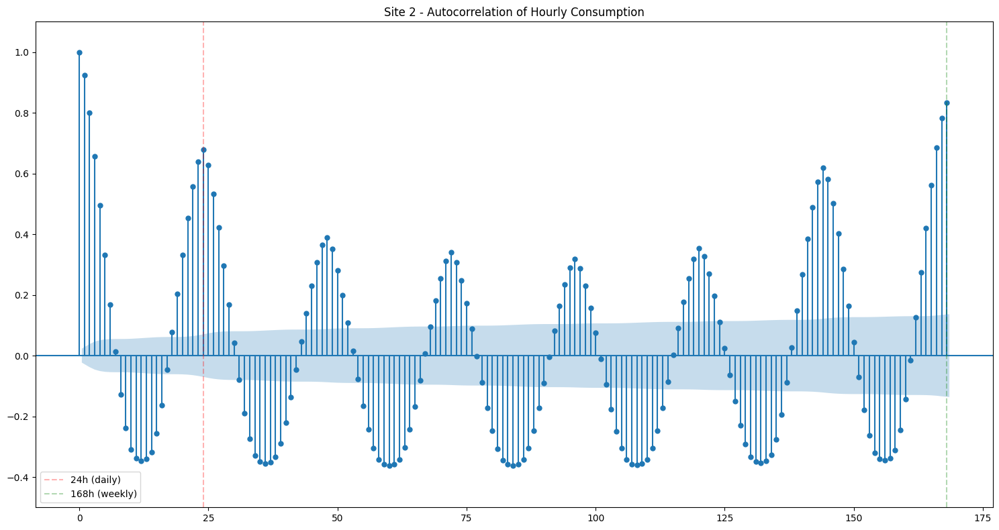

Site 2 - Top 7 ACF lags (abs ranking):
  Lag 1: +0.923
  Lag 168: +0.833
  Lag 2: +0.801
  Lag 167: +0.784
  Lag 166: +0.685
  Lag 24: +0.679
  Lag 3: +0.657


<Figure size 1500x600 with 0 Axes>

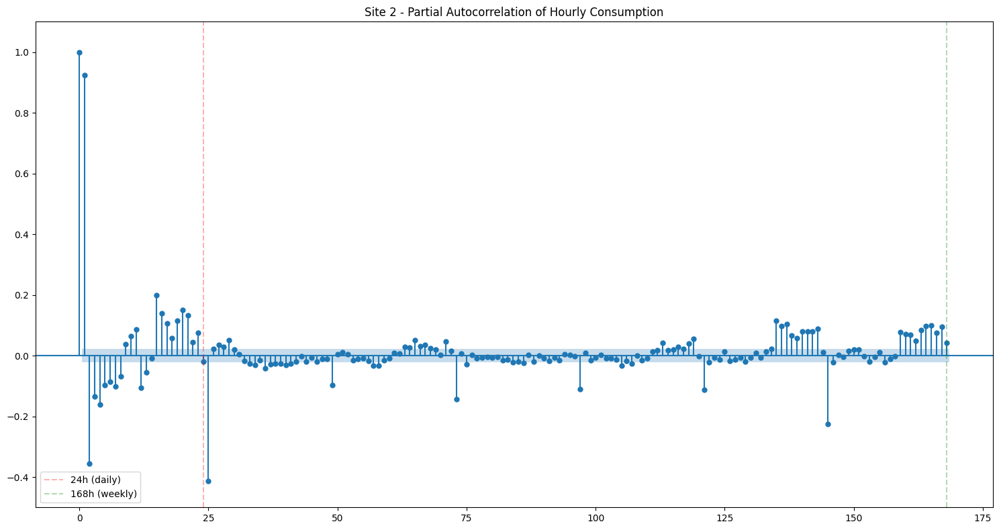

Site 2 - Top 7 PACF lags (abs ranking):
  Lag 1: +0.924
  Lag 25: -0.417
  Lag 2: -0.355
  Lag 145: -0.233
  Lag 15: +0.199
  Lag 4: -0.162
  Lag 20: +0.152

Autocorrelation Analysis for Site 3:


<Figure size 1500x600 with 0 Axes>

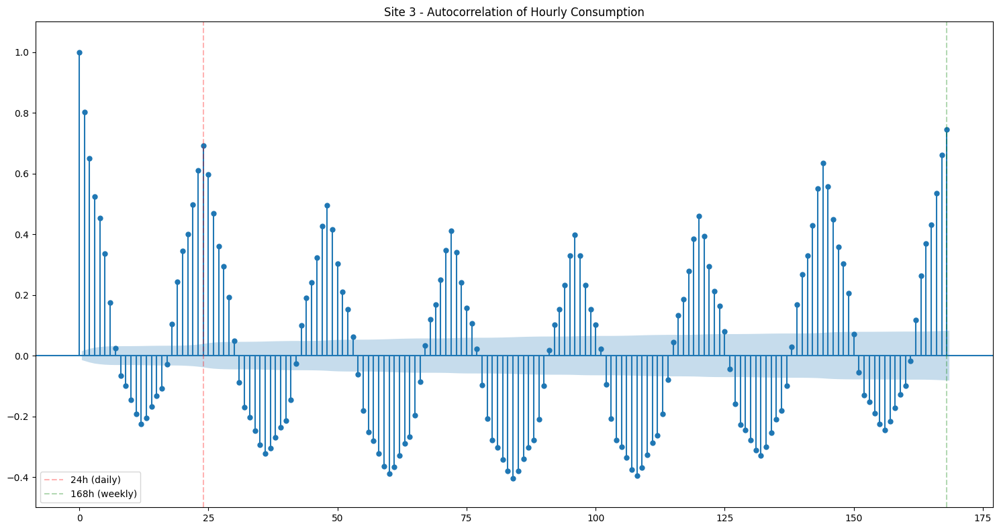

Site 3 - Top 7 ACF lags (abs ranking):
  Lag 1: +0.803
  Lag 168: +0.746
  Lag 24: +0.692
  Lag 167: +0.661
  Lag 2: +0.650
  Lag 144: +0.635
  Lag 23: +0.610


<Figure size 1500x600 with 0 Axes>

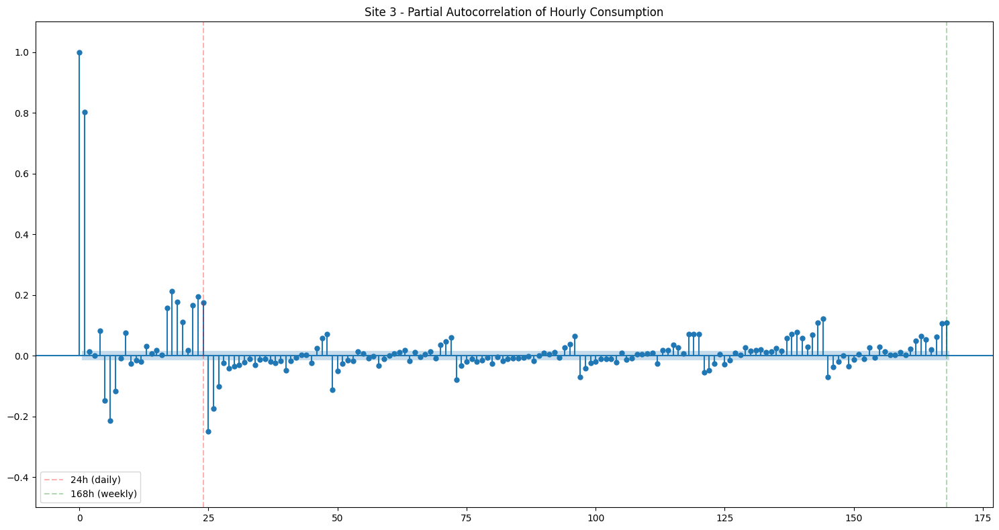

Site 3 - Top 7 PACF lags (abs ranking):
  Lag 1: +0.803
  Lag 25: -0.249
  Lag 6: -0.214
  Lag 18: +0.214
  Lag 23: +0.195
  Lag 19: +0.177
  Lag 24: +0.175

Autocorrelation Analysis for Site 4:


<Figure size 1500x600 with 0 Axes>

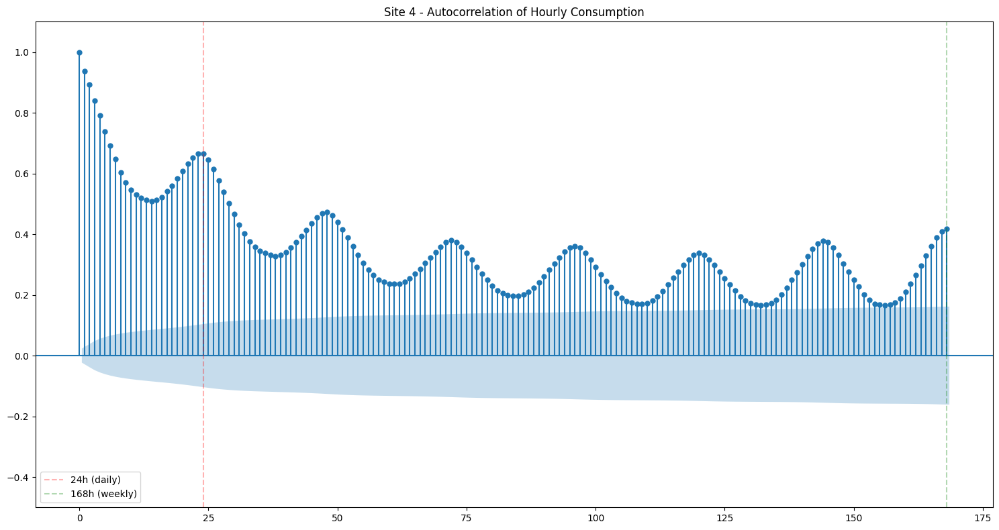

Site 4 - Top 7 ACF lags (abs ranking):
  Lag 1: +0.938
  Lag 2: +0.892
  Lag 3: +0.840
  Lag 4: +0.792
  Lag 5: +0.739
  Lag 6: +0.693
  Lag 23: +0.665


<Figure size 1500x600 with 0 Axes>

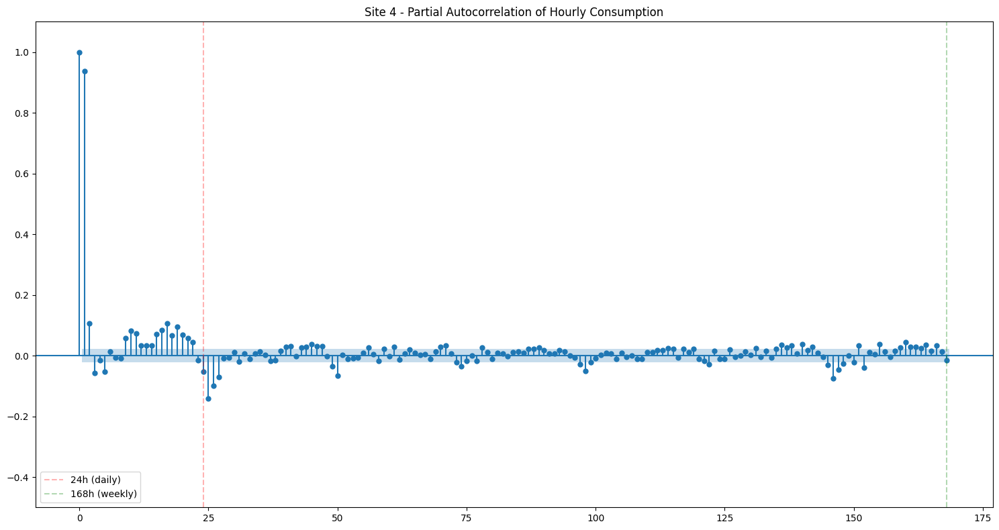

Site 4 - Top 7 PACF lags (abs ranking):
  Lag 1: +0.938
  Lag 25: -0.142
  Lag 17: +0.107
  Lag 2: +0.106
  Lag 26: -0.099
  Lag 19: +0.095
  Lag 16: +0.084

Autocorrelation Analysis for Site 5:


<Figure size 1500x600 with 0 Axes>

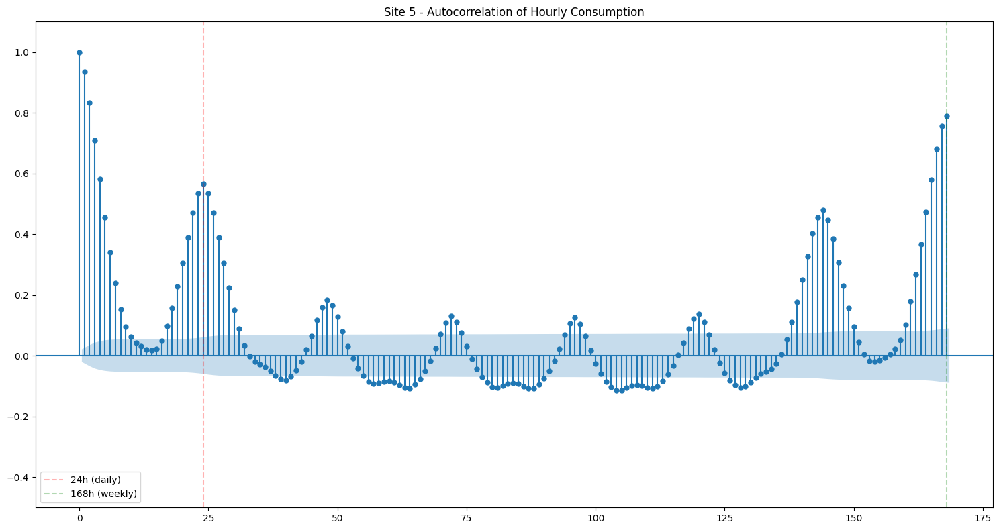

Site 5 - Top 7 ACF lags (abs ranking):
  Lag 1: +0.936
  Lag 2: +0.834
  Lag 168: +0.790
  Lag 167: +0.755
  Lag 3: +0.709
  Lag 166: +0.681
  Lag 4: +0.581


<Figure size 1500x600 with 0 Axes>

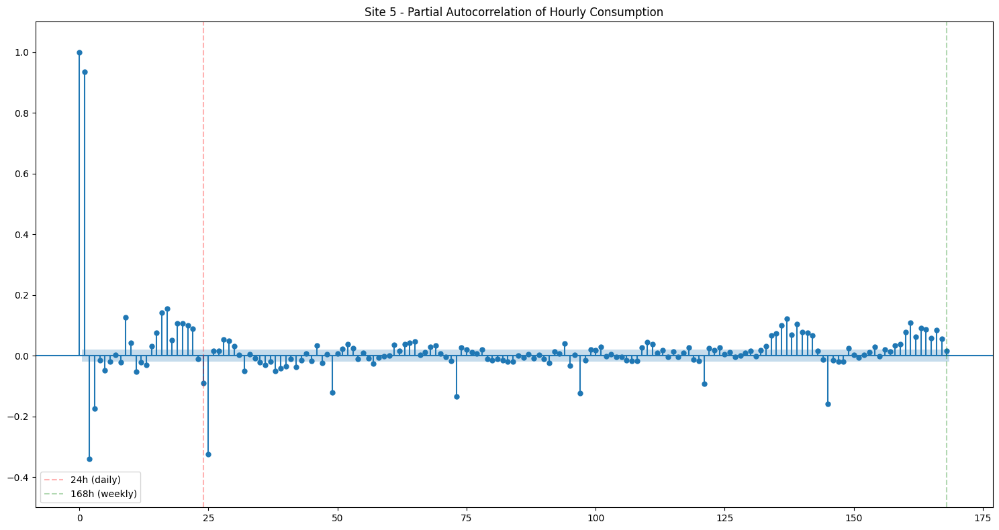

Site 5 - Top 7 PACF lags (abs ranking):
  Lag 1: +0.936
  Lag 2: -0.340
  Lag 25: -0.326
  Lag 3: -0.175
  Lag 145: -0.164
  Lag 17: +0.156
  Lag 16: +0.141

Autocorrelation Analysis for Site 6:


<Figure size 1500x600 with 0 Axes>

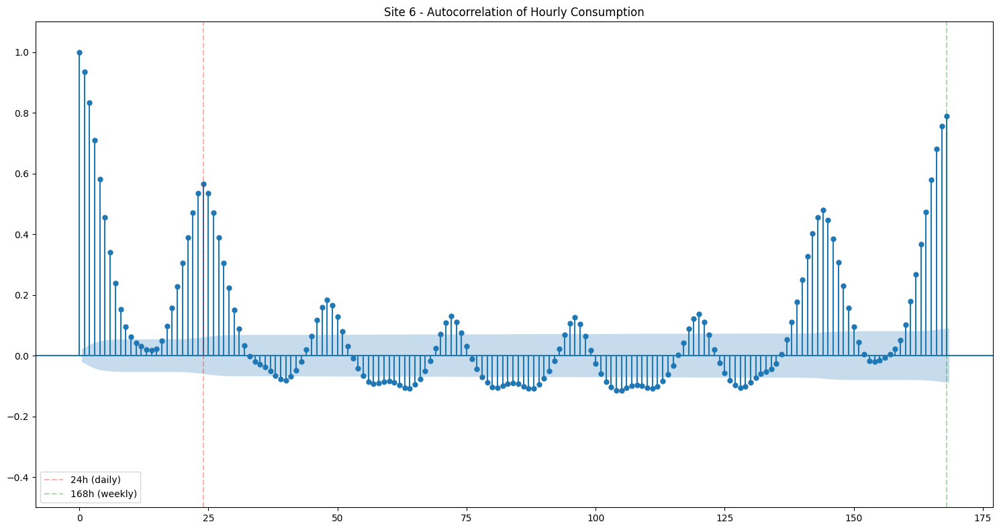

Site 6 - Top 7 ACF lags (abs ranking):
  Lag 1: +0.936
  Lag 2: +0.834
  Lag 168: +0.790
  Lag 167: +0.755
  Lag 3: +0.709
  Lag 166: +0.681
  Lag 4: +0.581


<Figure size 1500x600 with 0 Axes>

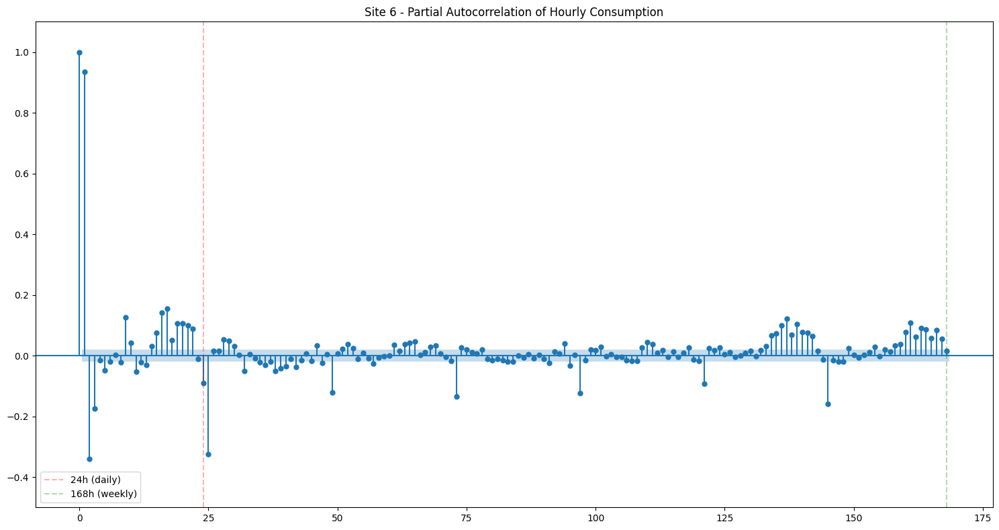

Site 6 - Top 7 PACF lags (abs ranking):
  Lag 1: +0.936
  Lag 2: -0.340
  Lag 25: -0.326
  Lag 3: -0.175
  Lag 145: -0.164
  Lag 17: +0.156
  Lag 16: +0.141

Autocorrelation Analysis for Site 7:


<Figure size 1500x600 with 0 Axes>

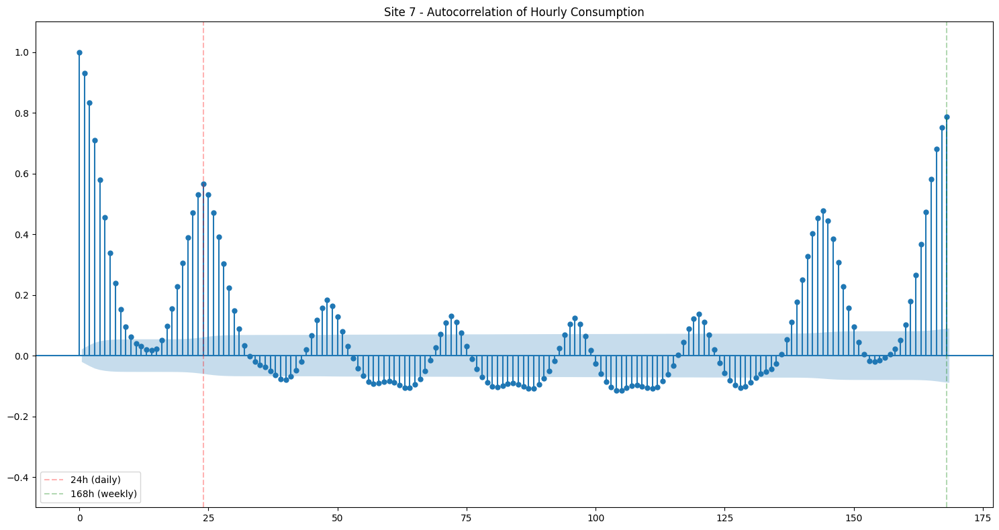

Site 7 - Top 7 ACF lags (abs ranking):
  Lag 1: +0.931
  Lag 2: +0.833
  Lag 168: +0.787
  Lag 167: +0.752
  Lag 3: +0.709
  Lag 166: +0.680
  Lag 165: +0.580


<Figure size 1500x600 with 0 Axes>

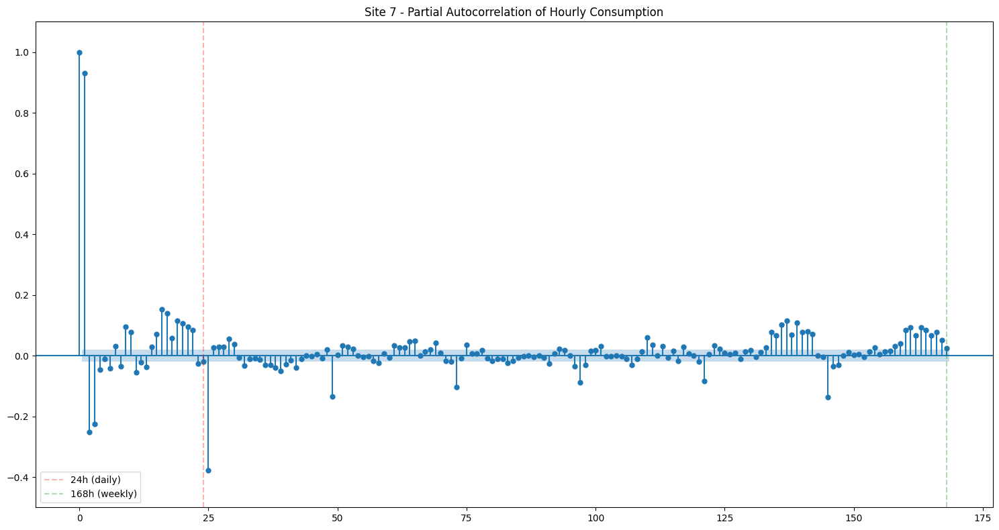

Site 7 - Top 7 PACF lags (abs ranking):
  Lag 1: +0.931
  Lag 25: -0.381
  Lag 2: -0.252
  Lag 3: -0.225
  Lag 16: +0.153
  Lag 145: -0.141
  Lag 17: +0.139

Autocorrelation Analysis for Site 8:


<Figure size 1500x600 with 0 Axes>

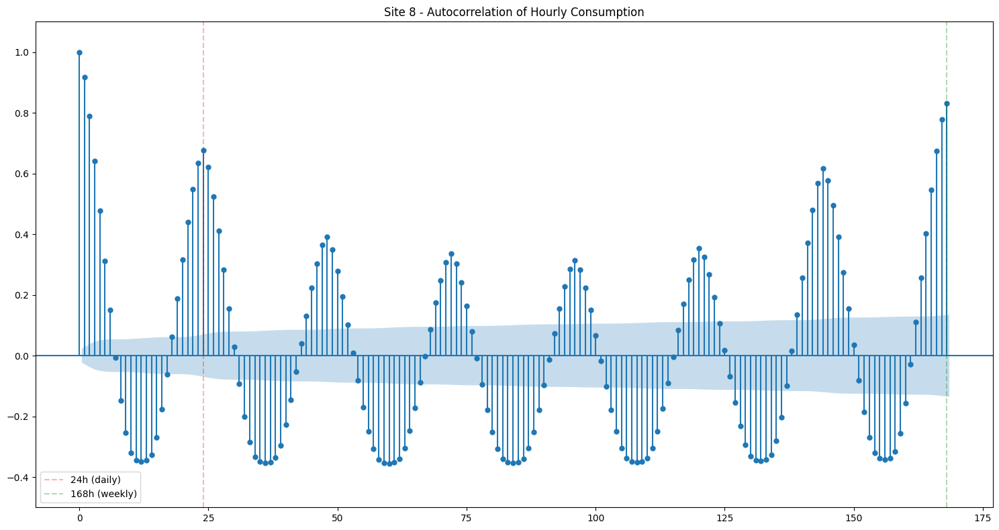

Site 8 - Top 7 ACF lags (abs ranking):
  Lag 1: +0.918
  Lag 168: +0.831
  Lag 2: +0.789
  Lag 167: +0.779
  Lag 24: +0.676
  Lag 166: +0.675
  Lag 3: +0.640


<Figure size 1500x600 with 0 Axes>

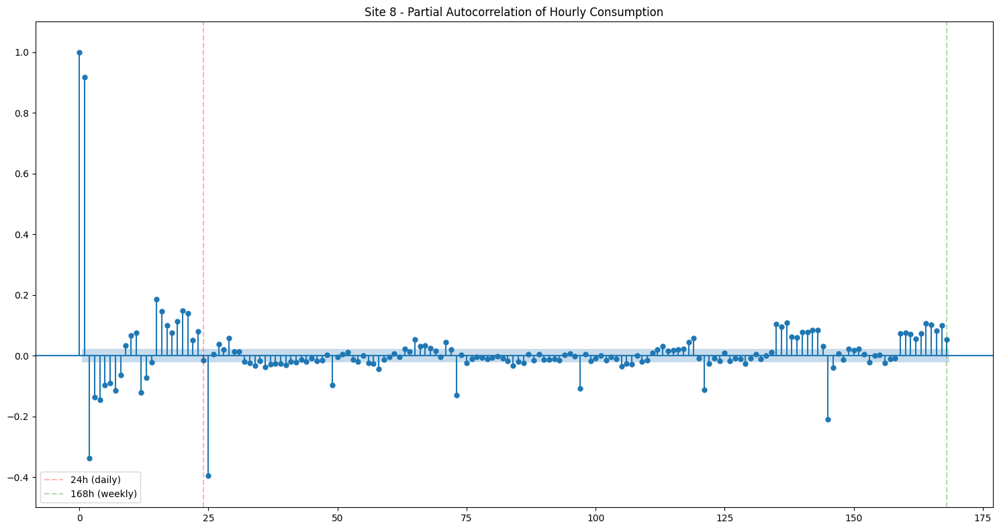

Site 8 - Top 7 PACF lags (abs ranking):
  Lag 1: +0.918
  Lag 25: -0.399
  Lag 2: -0.338
  Lag 145: -0.216
  Lag 15: +0.188
  Lag 20: +0.150
  Lag 16: +0.147

Autocorrelation Analysis for Site 9:


<Figure size 1500x600 with 0 Axes>

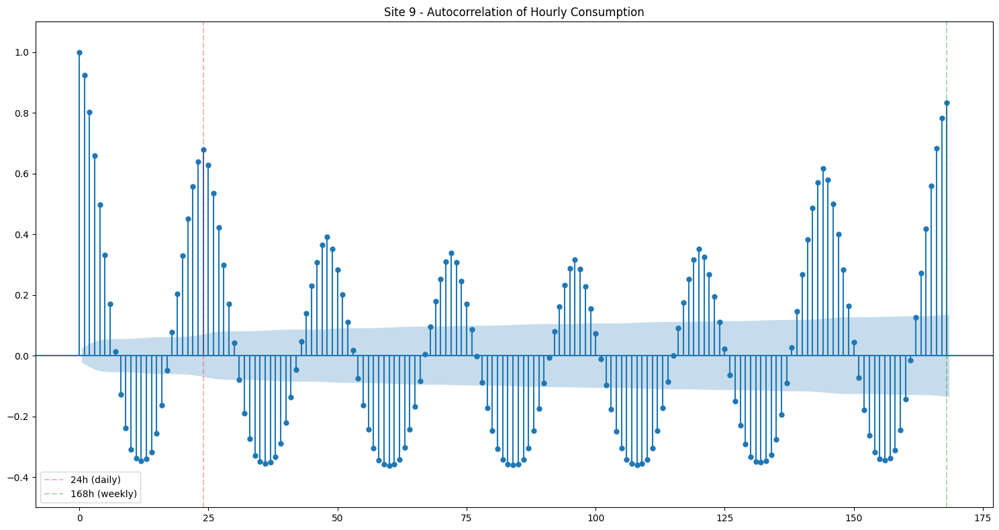

Site 9 - Top 7 ACF lags (abs ranking):
  Lag 1: +0.924
  Lag 168: +0.833
  Lag 2: +0.801
  Lag 167: +0.783
  Lag 166: +0.684
  Lag 24: +0.679
  Lag 3: +0.658


<Figure size 1500x600 with 0 Axes>

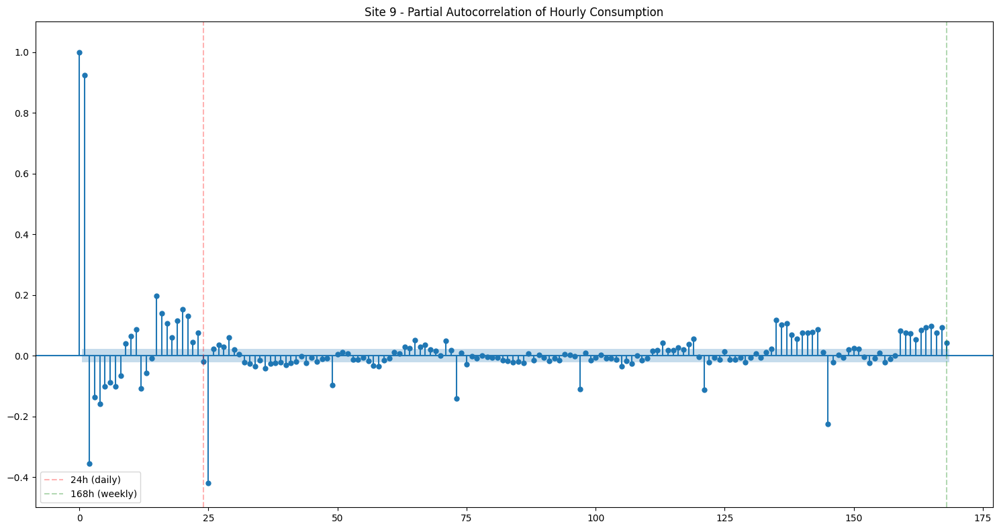

Site 9 - Top 7 PACF lags (abs ranking):
  Lag 1: +0.924
  Lag 25: -0.422
  Lag 2: -0.357
  Lag 145: -0.234
  Lag 15: +0.197
  Lag 4: -0.160
  Lag 20: +0.154


In [43]:
from statsmodels.tsa.stattools import acf, pacf

def plot_acf_pacf_consumption(series, site_id, lags=24*7):
    """Plot ACF and PACF for consumption data and print top correlations"""

    # Handle missing values
    fill_value = series.median() if not pd.isna(series.median()) else 0
    filled_series = series.fillna(fill_value)

    if len(filled_series) < lags:
        lags = len(filled_series) // 2

    # Compute ACF and PACF values
    acf_vals = acf(filled_series, nlags=lags, fft=True)
    pacf_vals = pacf(filled_series, nlags=lags)

    # Prepare lag indices (skip lag 0)
    lag_indices = np.arange(1, lags+1)
    acf_lags = acf_vals[1:]
    pacf_lags = pacf_vals[1:]

    # Get top 7 by absolute value for ACF and PACF
    def top_corr(lags_arr, vals_arr, top_n=7):
        abs_vals = np.abs(vals_arr)
        sorted_idx = np.argsort(-abs_vals)
        top_idx = sorted_idx[:top_n]
        return [(lags_arr[i], vals_arr[i]) for i in top_idx]

    # Plot ACF
    plt.figure(figsize=(15, 6))
    plot_acf(filled_series, lags=lags, title=f'Site {site_id} - Autocorrelation of Hourly Consumption')
    plt.ylim(-0.5, 1.1)
    plt.axvline(x=24, color='r', linestyle='--', alpha=0.3, label='24h (daily)')
    if lags >= 24*7:
        plt.axvline(x=24*7, color='g', linestyle='--', alpha=0.3, label='168h (weekly)')
    plt.legend()
    plt.tight_layout()
    plt.show()
    
    # Get top 7 by absolute value for ACF
    top_acf = top_corr(lag_indices, acf_lags)
    print(f"Site {site_id} - Top 7 ACF lags (abs ranking):")
    for lag, val in top_acf:
        print(f"  Lag {lag}: {val:+.3f}")

    # Plot PACF
    plt.figure(figsize=(15, 6))
    plot_pacf(filled_series, lags=lags, title=f'Site {site_id} - Partial Autocorrelation of Hourly Consumption')
    plt.ylim(-0.5, 1.1)
    plt.axvline(x=24, color='r', linestyle='--', alpha=0.3, label='24h (daily)')
    if lags >= 24*7:
        plt.axvline(x=24*7, color='g', linestyle='--', alpha=0.3, label='168h (weekly)')
    plt.legend()
    plt.tight_layout()
    plt.show()
    
    # Get top 7 by absolute value for PACF
    top_pacf = top_corr(lag_indices, pacf_lags)
    print(f"Site {site_id} - Top 7 PACF lags (abs ranking):")
    for lag, val in top_pacf:
        print(f"  Lag {lag}: {val:+.3f}")

# Perform autocorrelation analysis for each site
for i in range(1, len(site_hourly_data.keys())+1):
    site_key = f'site_{i}'
    if site_key in site_hourly_data:
        print(f"\nAutocorrelation Analysis for Site {i}:")
        plot_acf_pacf_consumption(site_hourly_data[site_key], i)


STL Decomposition for Site 1:


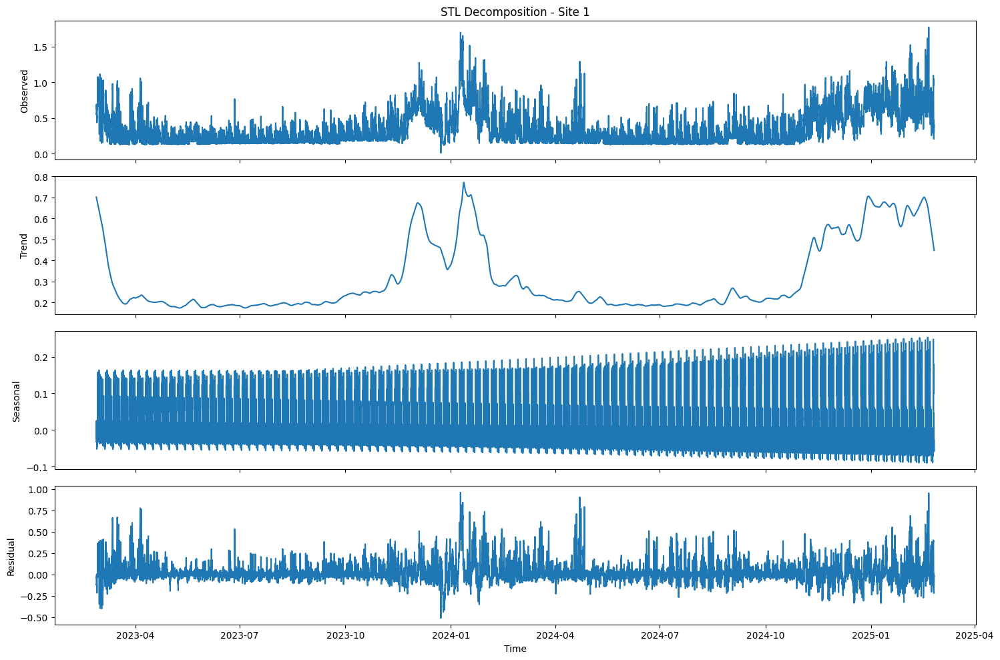


STL Decomposition for Site 2:


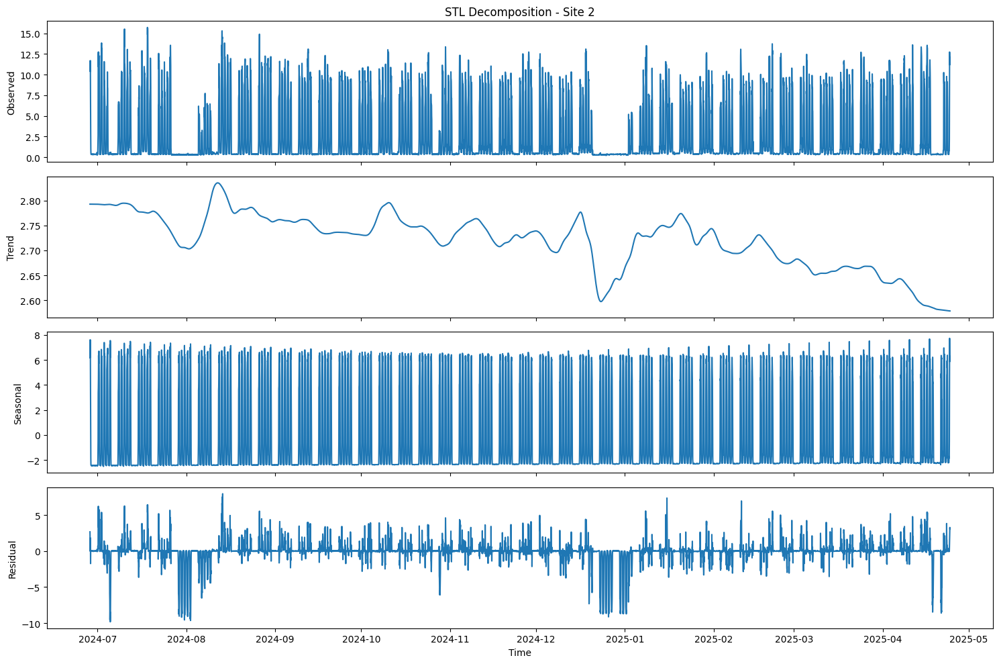


STL Decomposition for Site 3:


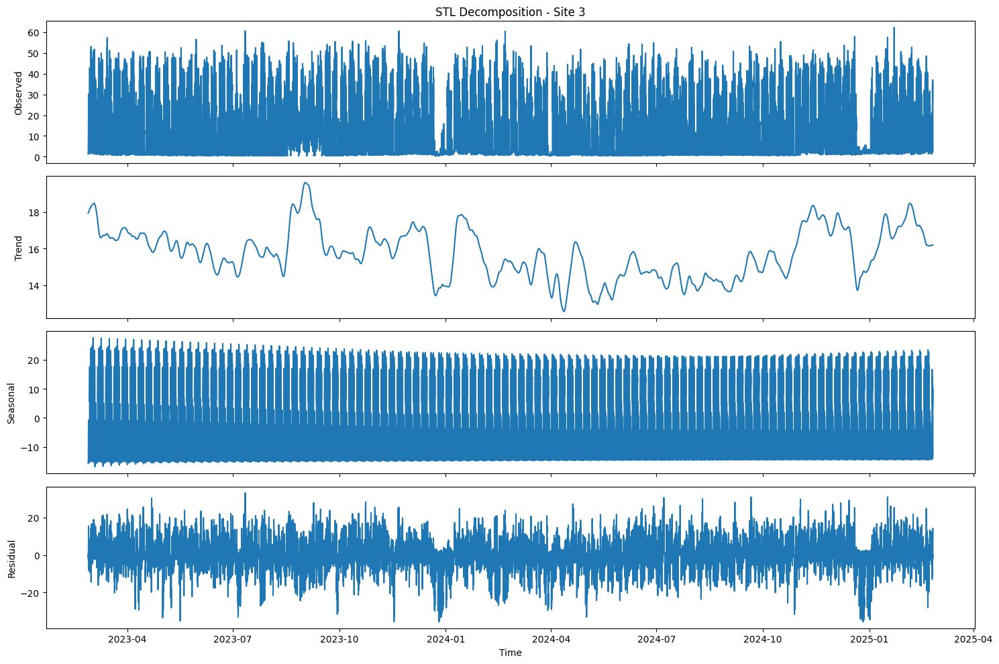


STL Decomposition for Site 4:


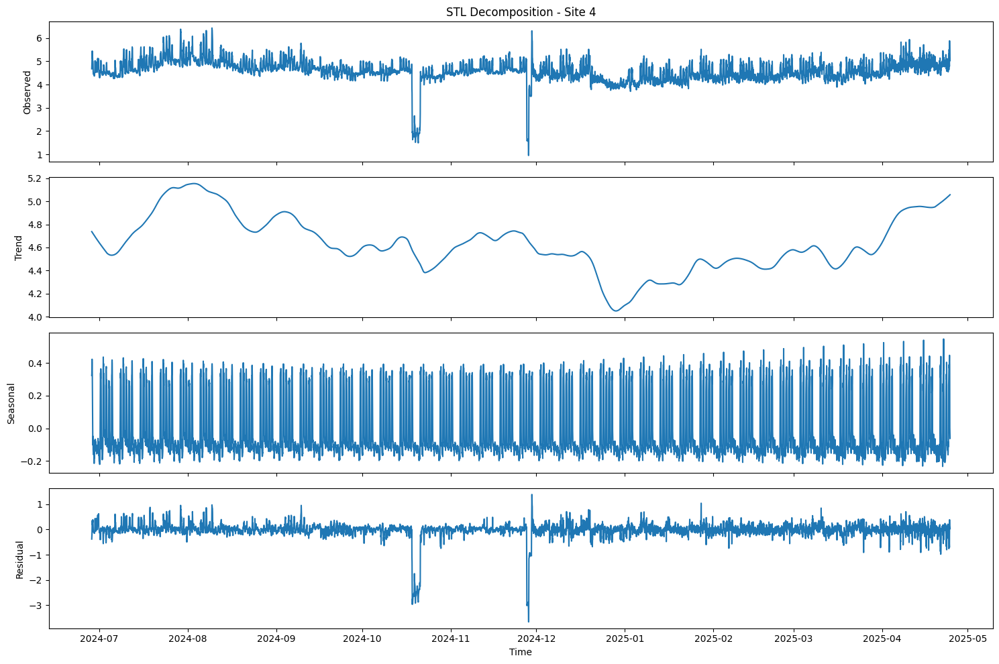


STL Decomposition for Site 5:


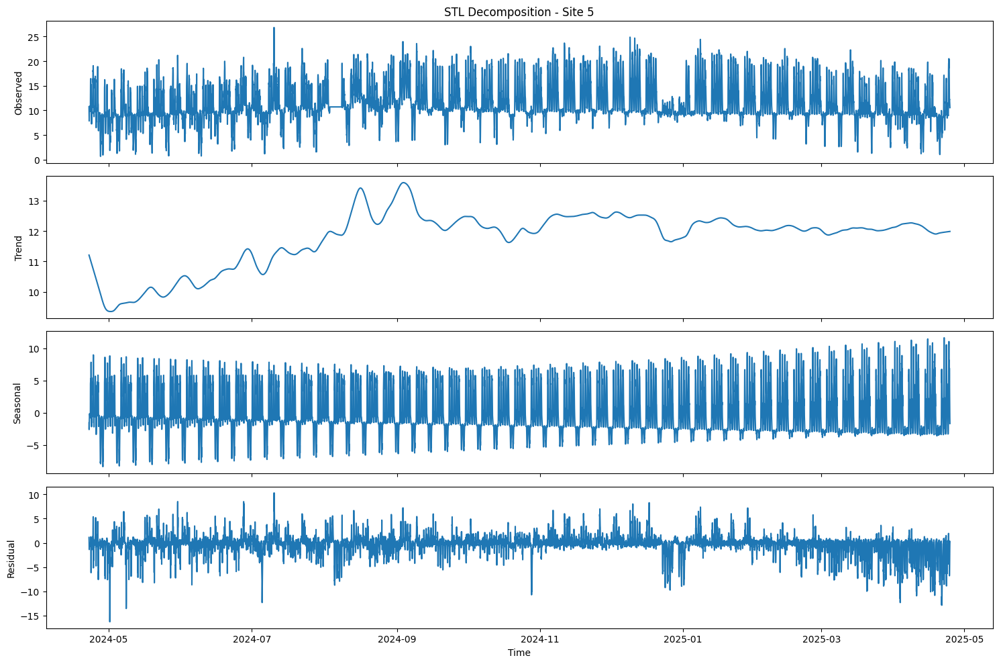


STL Decomposition for Site 6:


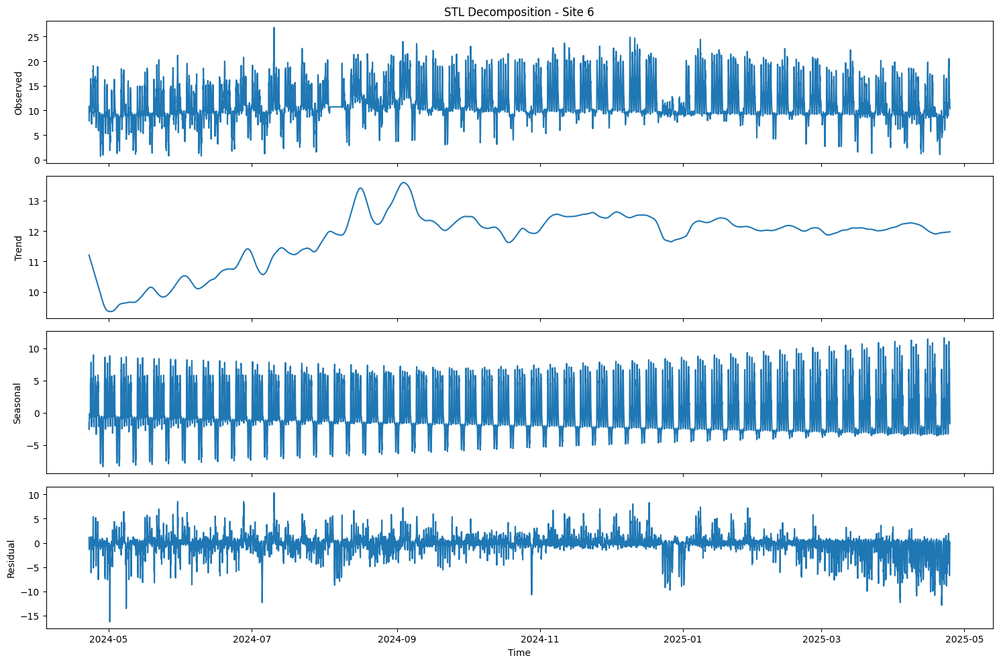


STL Decomposition for Site 7:


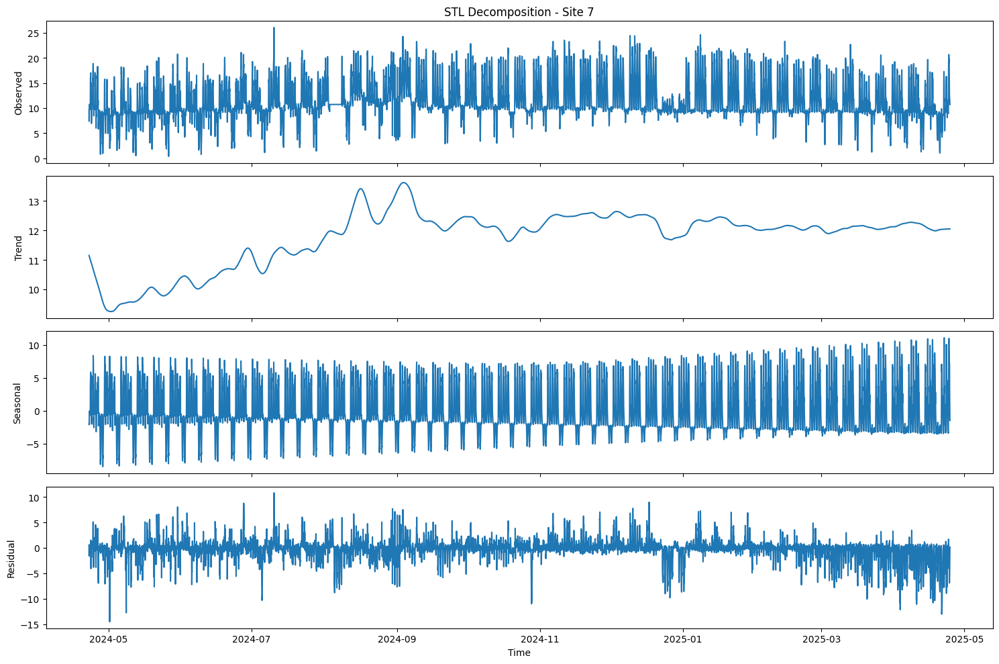


STL Decomposition for Site 8:


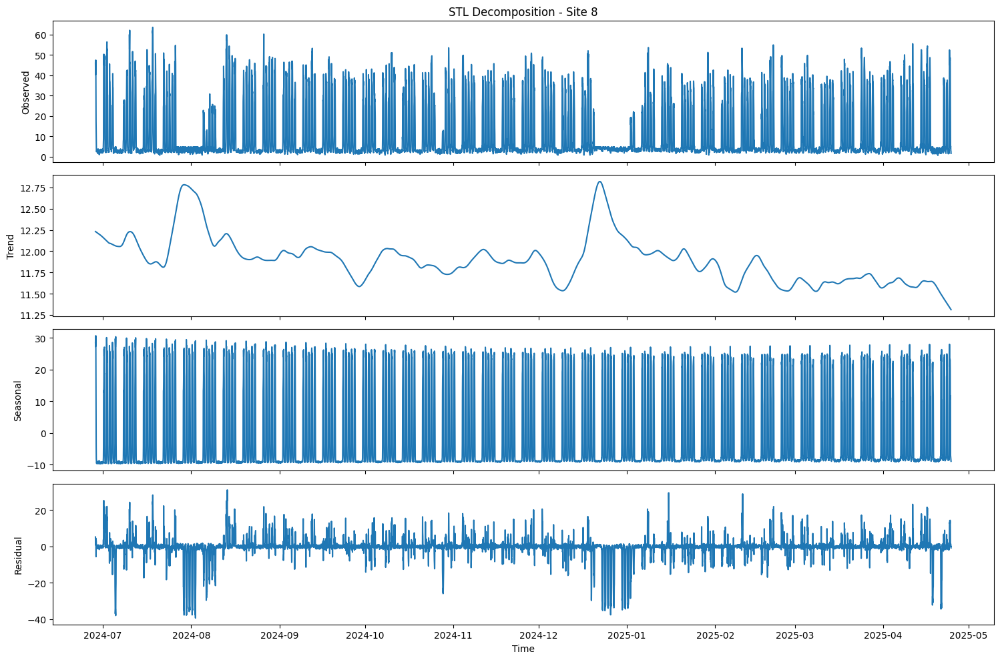


STL Decomposition for Site 9:


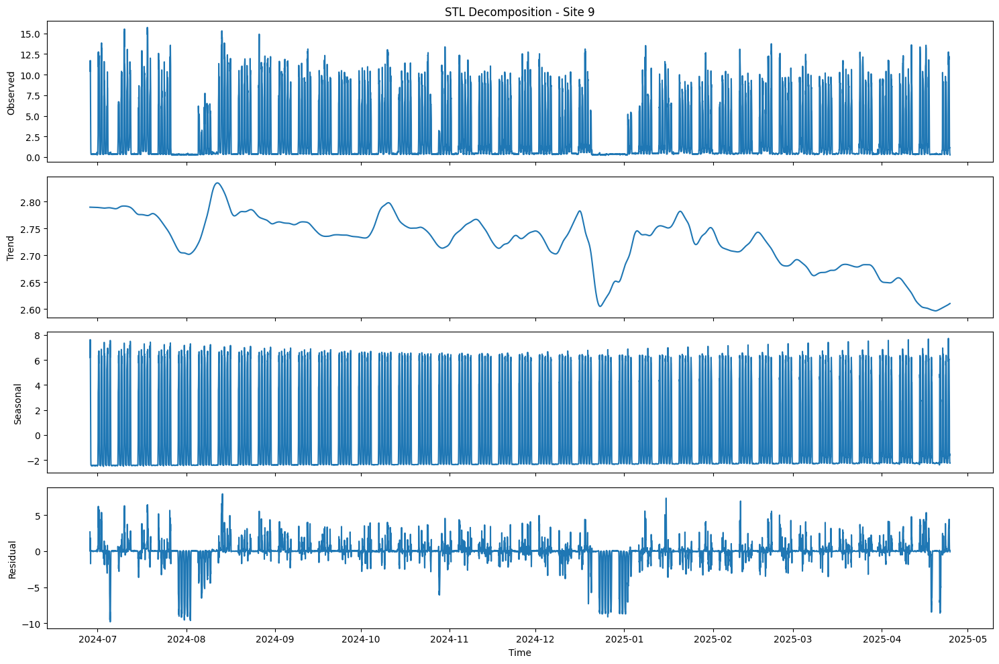

In [44]:
from statsmodels.tsa.seasonal import STL

import matplotlib.dates as mdates

def plot_stl_decomposition(series, site_id, period=168, robust=True):
    """Plot STL decomposition for a given time series."""
    # Fill missing values with median for decomposition
    fill_value = series.median() if not pd.isna(series.median()) else 0
    filled_series = series.fillna(fill_value)

    stl = STL(filled_series, period=period, seasonal=int(1.5*period)-1, robust=robust)
    result = stl.fit()

    fig, axes = plt.subplots(4, 1, figsize=(15, 10), sharex=True)
    axes[0].plot(result.observed)
    axes[0].set_ylabel("Observed")
    axes[1].plot(result.trend)
    axes[1].set_ylabel("Trend")
    axes[2].plot(result.seasonal)
    axes[2].set_ylabel("Seasonal")
    axes[3].plot(result.resid)
    axes[3].set_ylabel("Residual")
    axes[3].set_xlabel("Time")
    axes[0].set_title(f"STL Decomposition - Site {site_id}")
    plt.tight_layout()
    plt.show()

# STL decomposition for each site's hourly data
for i in range(1, len(site_hourly_data.keys())+1):
    site_key = f'site_{i}'
    if site_key in site_hourly_data:
        print(f"\nSTL Decomposition for Site {i}:")
        plot_stl_decomposition(site_hourly_data[site_key], i, period=168)

## 15m Analysis by Site

## Autocorrelation Analysis by Site


Autocorrelation Analysis for Site 1:


<Figure size 1500x600 with 0 Axes>

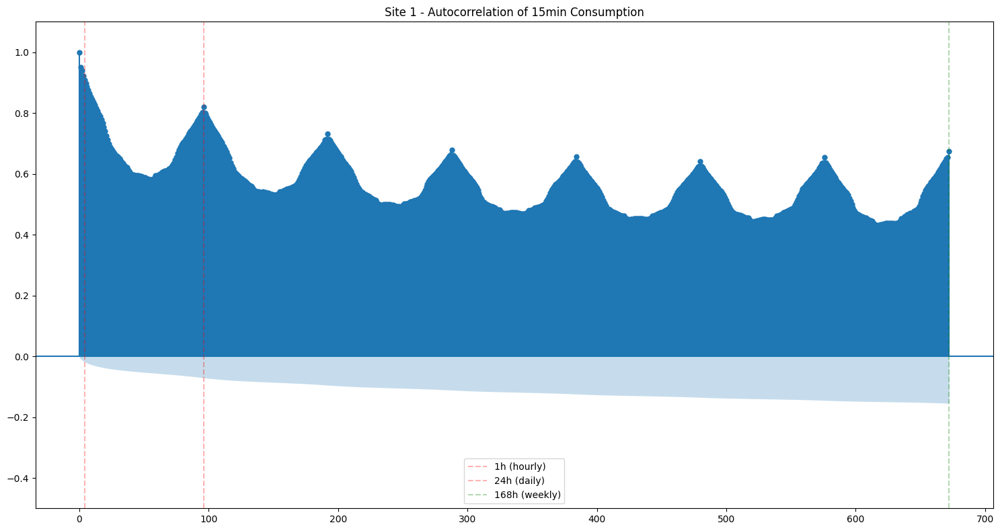

Site 1 - Top 7 ACF lags (abs ranking):
  Lag 1: +0.951
  Lag 2: +0.939
  Lag 3: +0.922
  Lag 4: +0.909
  Lag 5: +0.897
  Lag 6: +0.886
  Lag 7: +0.875


<Figure size 1500x600 with 0 Axes>

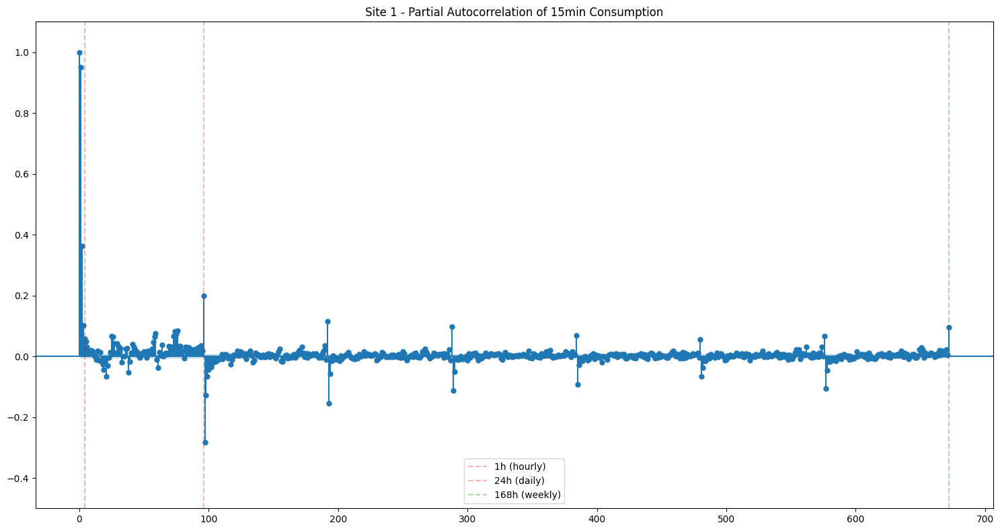

Site 1 - Top 7 PACF lags (abs ranking):
  Lag 1: +0.951
  Lag 2: +0.363
  Lag 97: -0.282
  Lag 96: +0.200
  Lag 193: -0.155
  Lag 98: -0.128
  Lag 192: +0.116

Autocorrelation Analysis for Site 2:


<Figure size 1500x600 with 0 Axes>

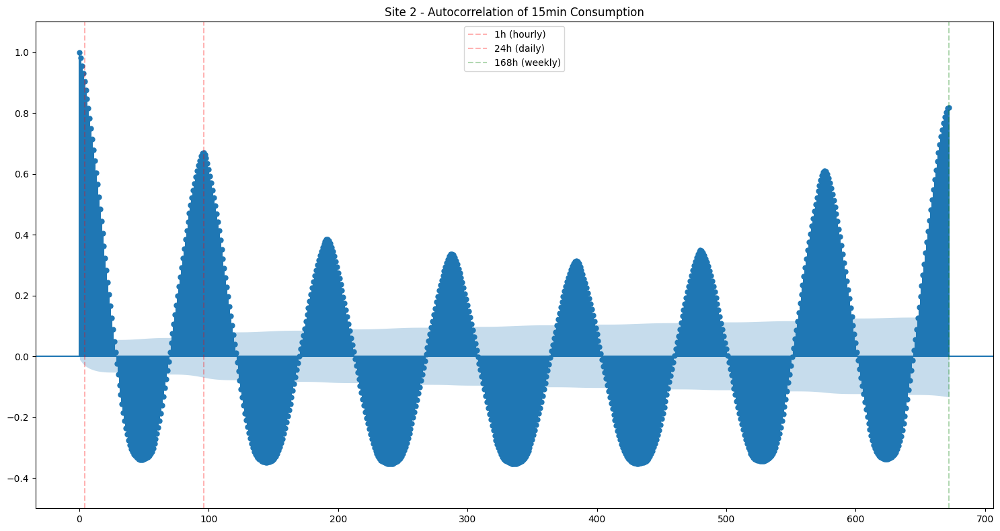

Site 2 - Top 7 ACF lags (abs ranking):
  Lag 1: +0.981
  Lag 2: +0.956
  Lag 3: +0.930
  Lag 4: +0.904
  Lag 5: +0.875
  Lag 6: +0.846
  Lag 672: +0.818


<Figure size 1500x600 with 0 Axes>

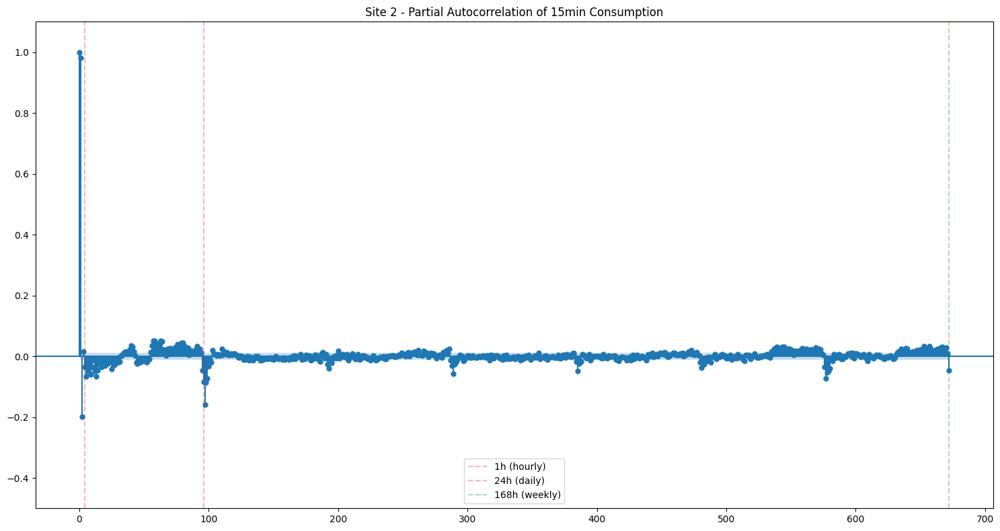

Site 2 - Top 7 PACF lags (abs ranking):
  Lag 1: +0.981
  Lag 2: -0.199
  Lag 97: -0.159
  Lag 98: -0.087
  Lag 96: -0.084
  Lag 99: -0.074
  Lag 577: -0.073

Autocorrelation Analysis for Site 3:


<Figure size 1500x600 with 0 Axes>

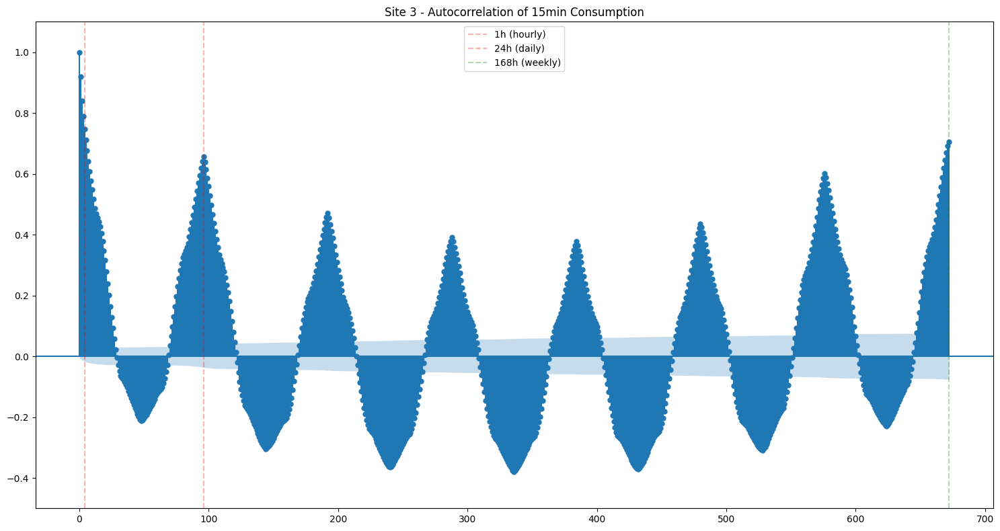

Site 3 - Top 7 ACF lags (abs ranking):
  Lag 1: +0.921
  Lag 2: +0.839
  Lag 3: +0.788
  Lag 4: +0.747
  Lag 5: +0.713
  Lag 672: +0.706
  Lag 671: +0.692


<Figure size 1500x600 with 0 Axes>

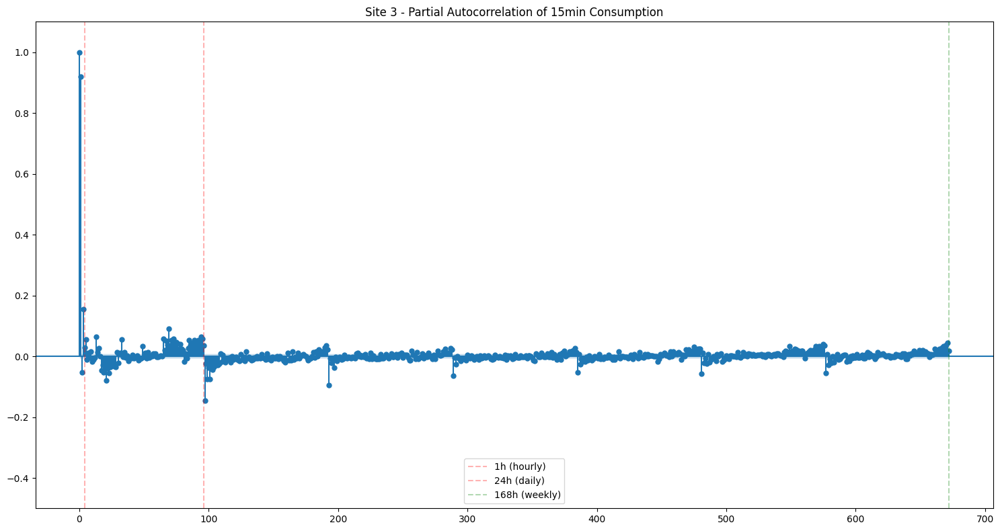

Site 3 - Top 7 PACF lags (abs ranking):
  Lag 1: +0.921
  Lag 3: +0.156
  Lag 97: -0.146
  Lag 193: -0.095
  Lag 69: +0.090
  Lag 21: -0.079
  Lag 101: -0.076

Autocorrelation Analysis for Site 4:


<Figure size 1500x600 with 0 Axes>

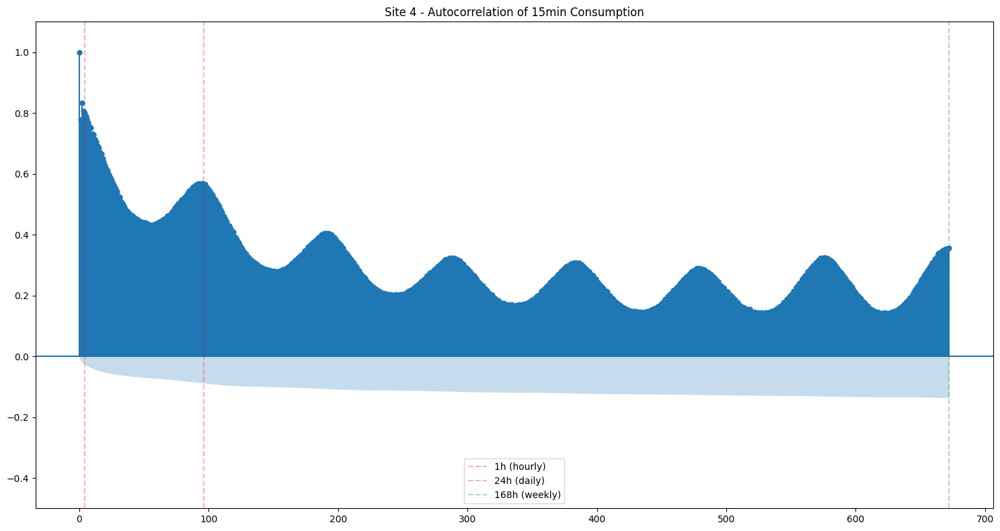

Site 4 - Top 7 ACF lags (abs ranking):
  Lag 2: +0.834
  Lag 3: +0.808
  Lag 4: +0.800
  Lag 5: +0.790
  Lag 6: +0.781
  Lag 1: +0.778
  Lag 7: +0.769


<Figure size 1500x600 with 0 Axes>

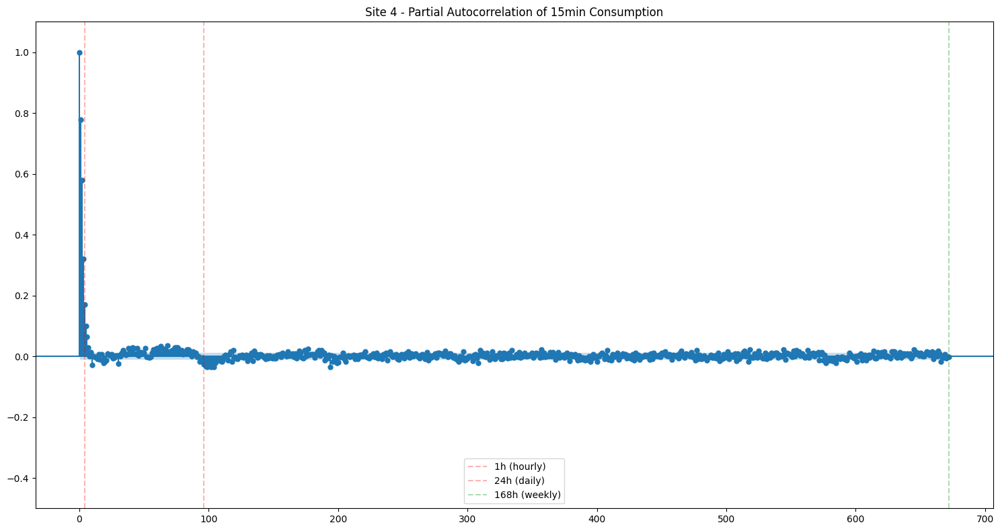

Site 4 - Top 7 PACF lags (abs ranking):
  Lag 1: +0.778
  Lag 2: +0.579
  Lag 3: +0.321
  Lag 4: +0.171
  Lag 5: +0.100
  Lag 6: +0.065
  Lag 99: -0.036

Autocorrelation Analysis for Site 5:


<Figure size 1500x600 with 0 Axes>

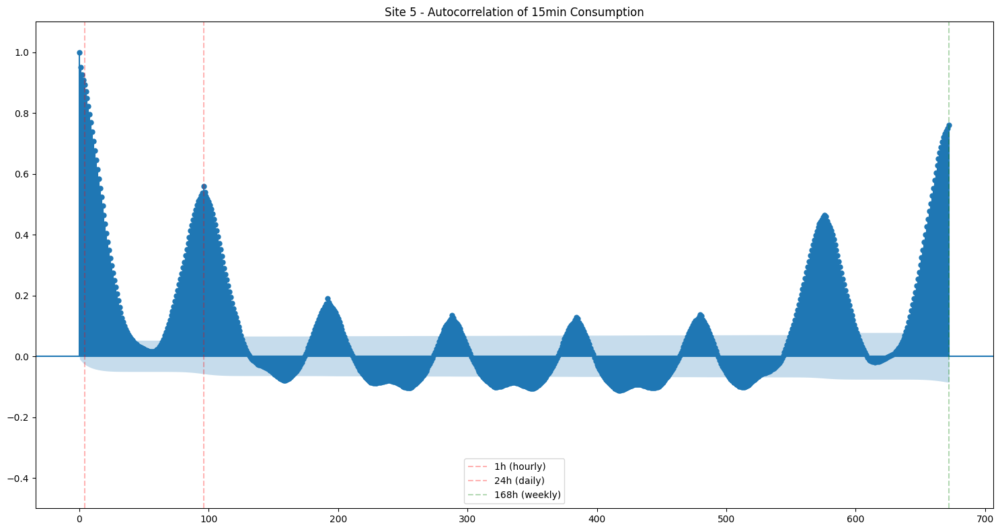

Site 5 - Top 7 ACF lags (abs ranking):
  Lag 1: +0.951
  Lag 2: +0.926
  Lag 3: +0.908
  Lag 4: +0.892
  Lag 5: +0.871
  Lag 6: +0.848
  Lag 7: +0.823


<Figure size 1500x600 with 0 Axes>

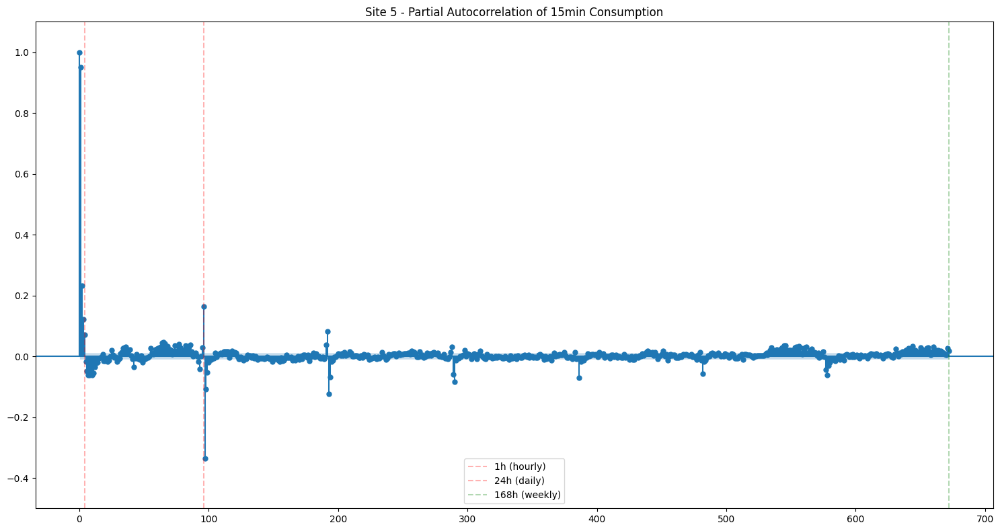

Site 5 - Top 7 PACF lags (abs ranking):
  Lag 1: +0.951
  Lag 97: -0.337
  Lag 2: +0.233
  Lag 96: +0.164
  Lag 193: -0.124
  Lag 3: +0.121
  Lag 98: -0.110

Autocorrelation Analysis for Site 6:


<Figure size 1500x600 with 0 Axes>

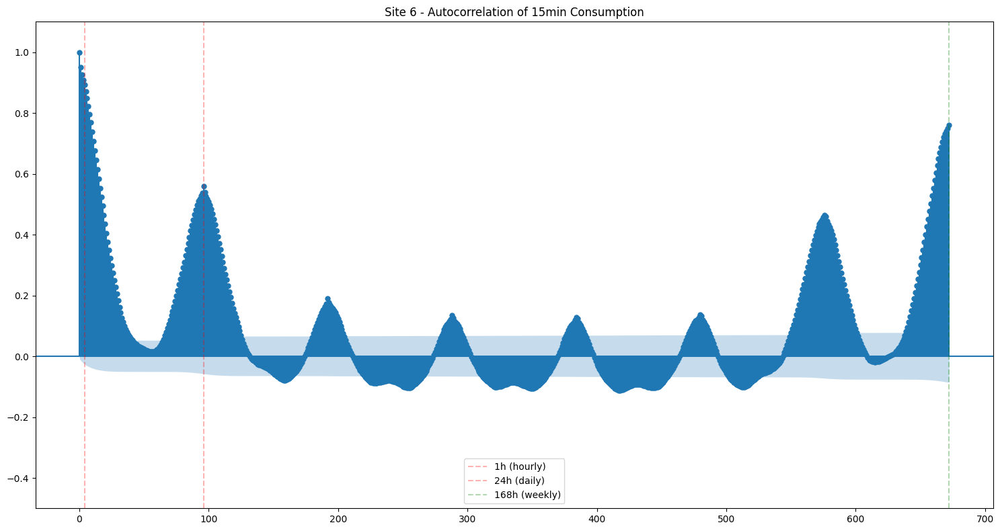

Site 6 - Top 7 ACF lags (abs ranking):
  Lag 1: +0.951
  Lag 2: +0.926
  Lag 3: +0.908
  Lag 4: +0.892
  Lag 5: +0.871
  Lag 6: +0.848
  Lag 7: +0.823


<Figure size 1500x600 with 0 Axes>

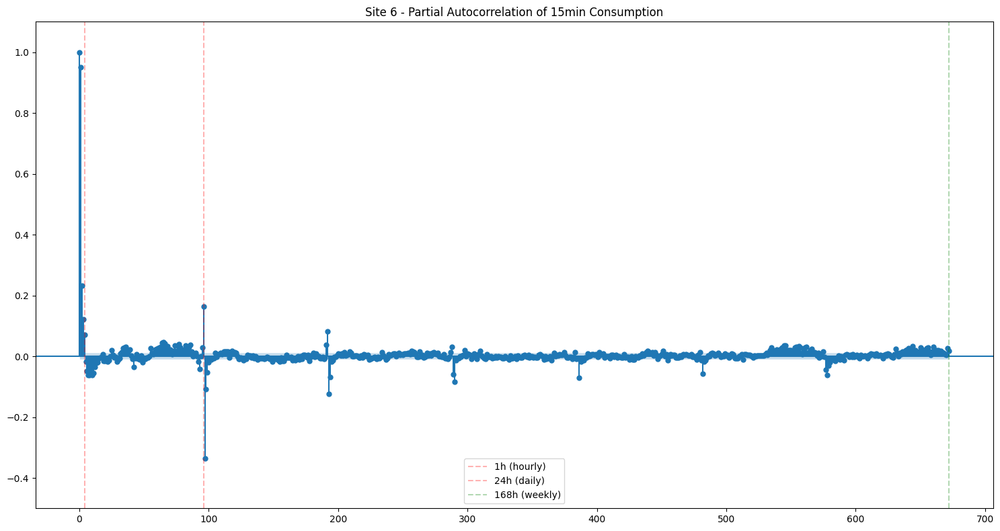

Site 6 - Top 7 PACF lags (abs ranking):
  Lag 1: +0.951
  Lag 97: -0.337
  Lag 2: +0.233
  Lag 96: +0.164
  Lag 193: -0.124
  Lag 3: +0.121
  Lag 98: -0.110

Autocorrelation Analysis for Site 7:


<Figure size 1500x600 with 0 Axes>

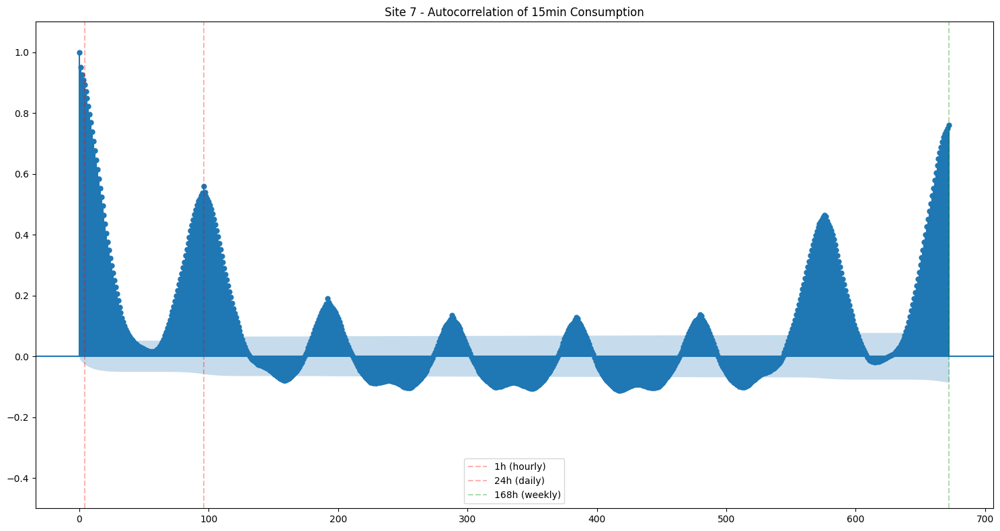

Site 7 - Top 7 ACF lags (abs ranking):
  Lag 1: +0.951
  Lag 2: +0.926
  Lag 3: +0.908
  Lag 4: +0.892
  Lag 5: +0.871
  Lag 6: +0.848
  Lag 7: +0.823


<Figure size 1500x600 with 0 Axes>

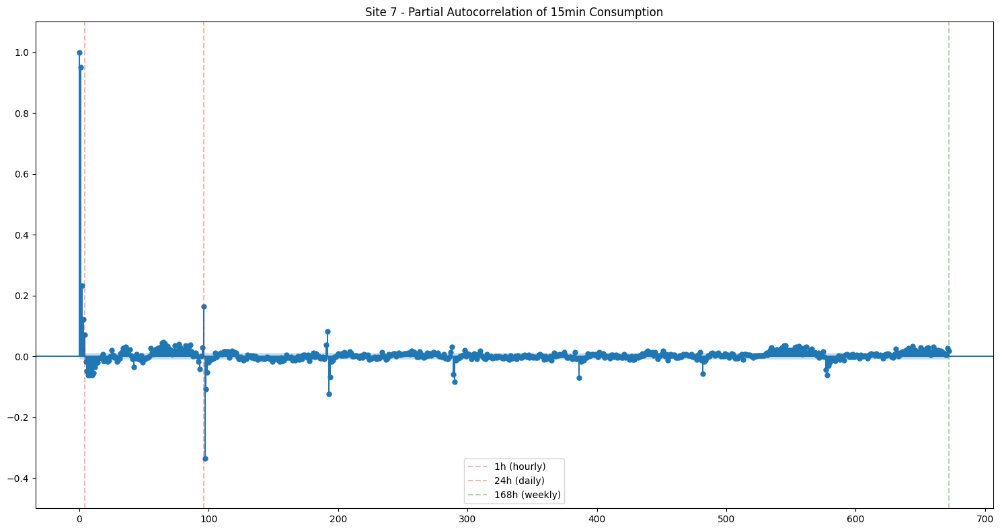

Site 7 - Top 7 PACF lags (abs ranking):
  Lag 1: +0.951
  Lag 97: -0.337
  Lag 2: +0.233
  Lag 96: +0.164
  Lag 193: -0.124
  Lag 3: +0.121
  Lag 98: -0.110

Autocorrelation Analysis for Site 8:


<Figure size 1500x600 with 0 Axes>

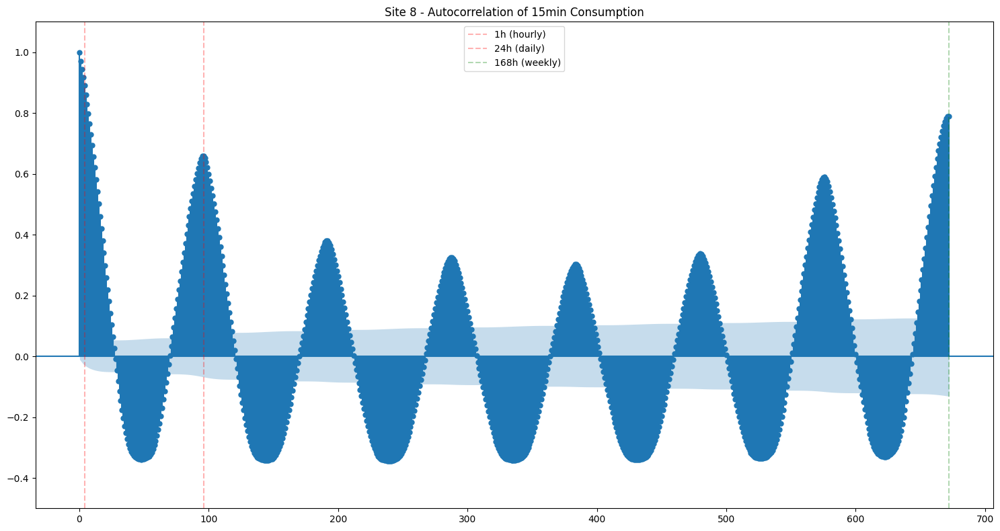

Site 8 - Top 7 ACF lags (abs ranking):
  Lag 1: +0.970
  Lag 2: +0.944
  Lag 3: +0.917
  Lag 4: +0.890
  Lag 5: +0.861
  Lag 6: +0.830
  Lag 7: +0.798


<Figure size 1500x600 with 0 Axes>

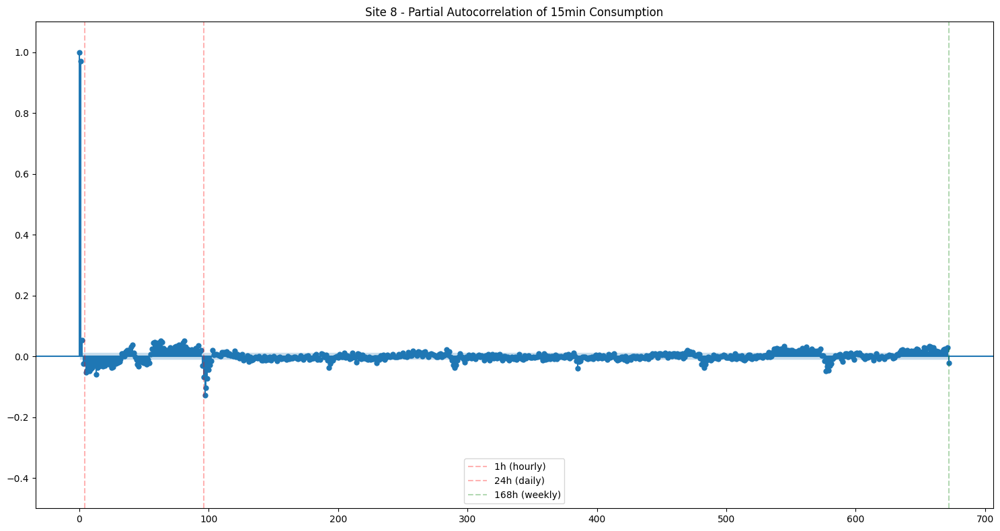

Site 8 - Top 7 PACF lags (abs ranking):
  Lag 1: +0.970
  Lag 97: -0.129
  Lag 98: -0.104
  Lag 99: -0.073
  Lag 96: -0.070
  Lag 13: -0.059
  Lag 5: -0.053

Autocorrelation Analysis for Site 9:


<Figure size 1500x600 with 0 Axes>

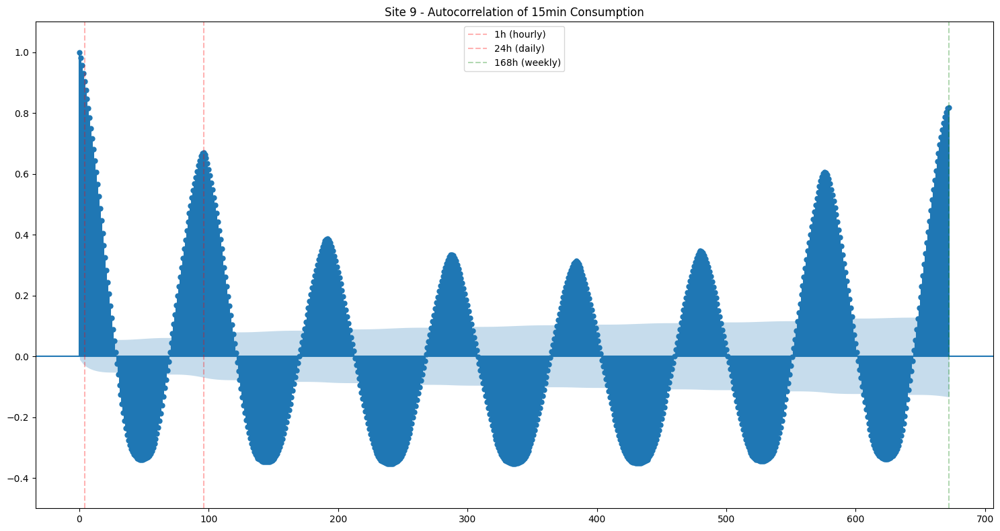

Site 9 - Top 7 ACF lags (abs ranking):
  Lag 1: +0.982
  Lag 2: +0.956
  Lag 3: +0.931
  Lag 4: +0.904
  Lag 5: +0.876
  Lag 6: +0.846
  Lag 672: +0.818


<Figure size 1500x600 with 0 Axes>

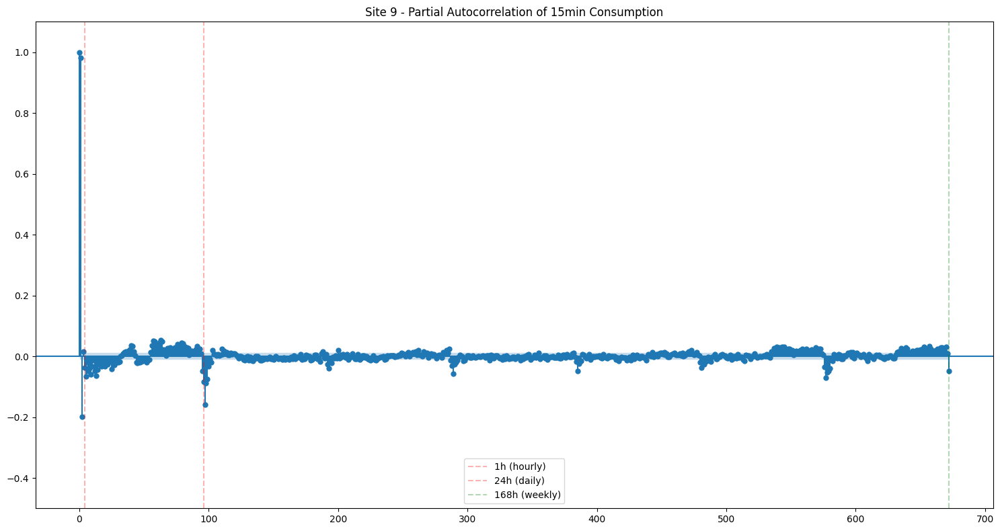

Site 9 - Top 7 PACF lags (abs ranking):
  Lag 1: +0.982
  Lag 2: -0.200
  Lag 97: -0.161
  Lag 98: -0.088
  Lag 96: -0.085
  Lag 99: -0.075
  Lag 577: -0.073


In [30]:
from statsmodels.tsa.stattools import acf, pacf

def plot_acf_pacf_consumption(series, site_id, lags=24*7):
    """Plot ACF and PACF for consumption data and print top correlations"""

    # Handle missing values
    fill_value = series.median() if not pd.isna(series.median()) else 0
    filled_series = series.fillna(fill_value)

    if len(filled_series) < lags:
        lags = len(filled_series) // 2

    # Compute ACF and PACF values
    acf_vals = acf(filled_series, nlags=lags, fft=True)
    pacf_vals = pacf(filled_series, nlags=lags)

    # Prepare lag indices (skip lag 0)
    lag_indices = np.arange(1, lags+1)
    acf_lags = acf_vals[1:]
    pacf_lags = pacf_vals[1:]

    # Get top 7 by absolute value for ACF and PACF
    def top_corr(lags_arr, vals_arr, top_n=7):
        abs_vals = np.abs(vals_arr)
        sorted_idx = np.argsort(-abs_vals)
        top_idx = sorted_idx[:top_n]
        return [(lags_arr[i], vals_arr[i]) for i in top_idx]

    # Plot ACF
    plt.figure(figsize=(15, 6))
    plot_acf(filled_series, lags=lags, title=f'Site {site_id} - Autocorrelation of 15min Consumption')
    plt.ylim(-0.5, 1.1)
    plt.axvline(x=4, color='r', linestyle='--', alpha=0.3, label='1h (hourly)')
    plt.axvline(x=24*4, color='r', linestyle='--', alpha=0.3, label='24h (daily)')
    if lags >= 24*7:
        plt.axvline(x=24*7*4, color='g', linestyle='--', alpha=0.3, label='168h (weekly)')
    plt.legend()
    plt.tight_layout()
    plt.show()
    
    # Get top 7 by absolute value for ACF
    top_acf = top_corr(lag_indices, acf_lags)
    print(f"Site {site_id} - Top 7 ACF lags (abs ranking):")
    for lag, val in top_acf:
        print(f"  Lag {lag}: {val:+.3f}")

    # Plot PACF
    plt.figure(figsize=(15, 6))
    plot_pacf(filled_series, lags=lags, title=f'Site {site_id} - Partial Autocorrelation of 15min Consumption')
    plt.ylim(-0.5, 1.1)
    plt.axvline(x=4, color='r', linestyle='--', alpha=0.3, label='1h (hourly)')
    plt.axvline(x=24*4, color='r', linestyle='--', alpha=0.3, label='24h (daily)')
    if lags >= 24*7:
        plt.axvline(x=24*7*4, color='g', linestyle='--', alpha=0.3, label='168h (weekly)')
    plt.legend()
    plt.tight_layout()
    plt.show()
    
    # Get top 7 by absolute value for PACF
    top_pacf = top_corr(lag_indices, pacf_lags)
    print(f"Site {site_id} - Top 7 PACF lags (abs ranking):")
    for lag, val in top_pacf:
        print(f"  Lag {lag}: {val:+.3f}")

# Perform autocorrelation analysis for each site
for site in list_of_sites:
    site_id = site['site_id'].iloc[0]
    print(f"\nAutocorrelation Analysis for Site {site_id}:")
    plot_acf_pacf_consumption(site['consumption'], site_id, lags=24*7*4)